[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Gui-Domenico-UFMG/ia-generativa-ufmg-latent-flow/blob/main/notebooks/final_task.ipynb)

#**Final Task - Latent Diffusion/Flow for the EMNIST dataset**

  **Authors**: Guilherme Martins Dijan Domenico, João Paulo Lara Pinto, Fábio



This notebook explores generative modeling on the EMNIST dataset through a two-stage latent flow architecture:


1. **Latent Space Modeling:** We first train a VAE to learn a continuous latent representation of the dataset.
2.   **Flow Matching:** We train a velocity field model on top of the VAE's latent space. Generation involves sampling from $\mathcal{N}(0, I)$, letting the flow model shape the trajectory, and decoding the refined latent vector into pixel space.
3.   **Conditional Extension:** We scale the approach to a Conditional VAE (CVAE) with class embeddings, allowing for controlled, class-specific character generation.
4.   **Bonus — Classifier-Free Guidance:** a class-conditional velocity field $\Phi(z, t, c)$ trained with label dropout on the unconditional VAE latents, sampled with CFG.

The following cells outline the step-by-step implementation. For optimal performance, we recommend running this notebook in a GPU-accelerated environment.

In [ ]:
# SETUP: output folders used by the cells below (run this first)
import os
for d in ("data", "outputs", "cvae", "flow", "cfg_flow"):
    os.makedirs(d, exist_ok=True)

import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

## Functions to load and split the Dataset into train and test sets

In [2]:
import string
from typing import Tuple

import torch
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset

from torchvision import datasets, transforms

# Mapeamento das 36 classes: 0..9 -> '0'..'9', 10..35 -> 'A'..'Z'
CLASS_NAMES = list(string.digits) + list(string.ascii_uppercase)
NUM_CLASSES = 36
IMG_SHAPE = (1, 28, 28)


def index_to_char(idx: int) -> str:
    """Índice da classe (0..35) -> caractere ('0'-'9', 'A'-'Z')."""
    return CLASS_NAMES[idx] if 0 <= idx < NUM_CLASSES else "?"


def char_to_index(ch: str) -> int:
    """Caractere ('0'-'9' ou 'A'-'Z', sem diferenciar maiúscula/minúscula) -> índice 0..35."""
    ch = ch.upper()
    if ch in CLASS_NAMES:
        return CLASS_NAMES.index(ch)
    raise ValueError(f"Caractere '{ch}' inválido. Use '0'-'9' ou 'A'-'Z'.")


class TransposeEMNIST:
    """Corrige a orientação das imagens do EMNIST (troca altura e largura)."""

    def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
        return tensor.transpose(-2, -1).contiguous()


# Cópia pública dos arquivos originais do NIST (usada só se o download oficial falhar).
MIRROR_URL = "https://media.githubusercontent.com/media/aurelienduarte/emnist/master/gzip/"
MIRROR_FILES = [f"emnist-balanced-{s}-ubyte" for s in
                ("train-images-idx3", "train-labels-idx1", "test-images-idx3", "test-labels-idx1")]


def download_from_mirror(data_dir: str = "./data") -> None:
    """Baixa os 4 arquivos do split 'balanced' do espelho para data_dir/EMNIST/raw (formato do torchvision)."""
    import gzip
    import os
    import shutil
    import urllib.request

    raw = os.path.join(data_dir, "EMNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MIRROR_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        print(f"Baixando {name}.gz do espelho...")
        urllib.request.urlretrieve(MIRROR_URL + name + ".gz", dst + ".gz")
        with gzip.open(dst + ".gz", "rb") as fin, open(dst, "wb") as fout:
            shutil.copyfileobj(fin, fout)
        os.remove(dst + ".gz")


def get_emnist_36_datasets(data_dir: str = "./data") -> Tuple[Dataset, Dataset]:
    """Retorna (treino, teste) do EMNIST com as 36 classes, imagens em [0, 1] e orientação corrigida."""
    transform = transforms.Compose([transforms.ToTensor(), TransposeEMNIST()])

    def load(train: bool, download: bool):
        return datasets.EMNIST(root=data_dir, split="balanced", train=train, download=download, transform=transform)

    try:
        train_full, test_full = load(True, True), load(False, True)
    except Exception as e:  # site do NIST fora do ar ou bloqueado
        print(f"Download oficial falhou ({type(e).__name__}); usando o espelho.")
        download_from_mirror(data_dir)
        train_full, test_full = load(True, False), load(False, False)

    train_idx = torch.where(train_full.targets < NUM_CLASSES)[0].tolist()
    test_idx = torch.where(test_full.targets < NUM_CLASSES)[0].tolist()
    return Subset(train_full, train_idx), Subset(test_full, test_idx)


def get_fake_datasets(n_train: int = 2048, n_test: int = 512, seed: int = 0) -> Tuple[Dataset, Dataset]:
    """
    Dados falsos com o mesmo formato do EMNIST-36 (para testar o código sem baixar nada).
    Cada classe é um "borrão" numa posição diferente, para o VAE ter algo para aprender.
    """
    g = torch.Generator().manual_seed(seed)

    def make(n: int) -> TensorDataset:
        y = torch.randint(0, NUM_CLASSES, (n,), generator=g)
        yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")
        cy = 6 + (y // 6).float() * 3.2
        cx = 6 + (y % 6).float() * 3.2
        d2 = (yy[None] - cy[:, None, None]) ** 2 + (xx[None] - cx[:, None, None]) ** 2
        x = torch.exp(-d2 / 18.0) + 0.05 * torch.rand(n, 28, 28, generator=g)
        return TensorDataset(x.clamp(0, 1).unsqueeze(1), y)

    return make(n_train), make(n_test)


def get_dataloaders(
    data_dir: str = "./data",
    batch_size: int = 256,
    num_workers: int = 2,
    fake: bool = False,
) -> Tuple[DataLoader, DataLoader]:
    """DataLoaders de treino (embaralhado) e teste. Use fake=True para um teste rápido sem internet."""
    train_ds, test_ds = get_fake_datasets() if fake else get_emnist_36_datasets(data_dir)
    pin = torch.cuda.is_available()
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=pin, drop_last=True
    )
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin)
    return train_loader, test_loader

## Dataset samples visualization

In [3]:
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import torch

def _finish(fig, save_path: Optional[str], show: bool):
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        display(fig)
    plt.close(fig)


def plot_dataset_grid(images, labels, n: int = 36, save_path=None, show=True):
    """Grade com exemplos reais do dataset (confere orientação e rótulos)."""
    cols = 12
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.0, rows * 1.15))
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            ax.imshow(images[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            ax.set_title(index_to_char(int(labels[i])), fontsize=9)
    fig.suptitle("EMNIST-36 samples", fontsize=11)
    _finish(fig, save_path, show)

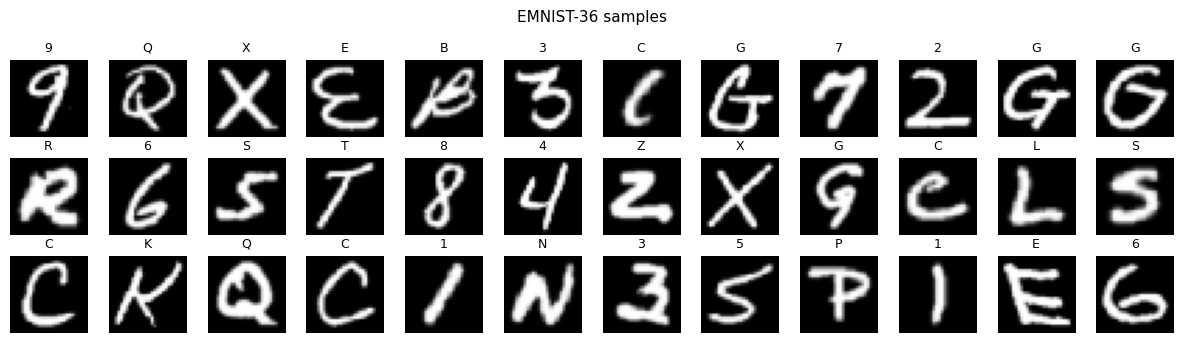

In [ ]:
train_dl, test_dl = get_dataloaders()
x_vis, y_vis = next(iter(test_dl))
plot_dataset_grid(x_vis, y_vis, save_path="dataset_grid.png", show=True)

## VAE definition

In [4]:
from typing import Dict, Tuple

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

class Encoder(nn.Module):
    """(B, 1, 28, 28) -> mu_E (B, m), log sigma_E (B, m) ou (B, 1)."""

    def __init__(self, latent_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()
        # (1, 28, 28) -> (32, 14, 14) -> (64, 7, 7) -> (128, 4, 4)
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.SiLU(),
            nn.Flatten(),
        )
        self.fc = nn.Sequential(nn.Linear(128 * 4 * 4, 256), nn.SiLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_log_sigma = nn.Linear(256, 1 if scalar_sigma else latent_dim)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        h = self.fc(self.conv(x))
        mu = self.fc_mu(h)
        log_sigma = self.fc_log_sigma(h).clamp(-10.0, 5.0)  # estabilidade numérica
        return mu, log_sigma


class Decoder(nn.Module):
    """(B, m) -> imagem (B, 1, 28, 28) em [0, 1]."""

    def __init__(self, latent_dim: int = 16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.SiLU(),
            nn.Linear(256, 128 * 7 * 7), nn.SiLU(),
        )
        # (128, 7, 7) -> (64, 14, 14) -> (32, 28, 28) -> (1, 28, 28)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.deconv(self.fc(z).view(-1, 128, 7, 7))


class VAE(nn.Module):
    def __init__(self, latent_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()
        self.latent_dim = latent_dim
        self.scalar_sigma = scalar_sigma
        self.encoder = Encoder(latent_dim, scalar_sigma)
        self.decoder = Decoder(latent_dim)

    @property
    def config(self) -> Dict:
        return {"latent_dim": self.latent_dim, "scalar_sigma": self.scalar_sigma}

    def encode(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """Retorna (mu_E(x), sigma_E(x)). sigma_E tem shape (B, m) ou (B, 1)."""
        mu, log_sigma = self.encoder(x)
        return mu, log_sigma.exp()

    @staticmethod
    def reparameterize(mu: torch.Tensor, sigma: torch.Tensor) -> torch.Tensor:
        """Z(x) = mu_E(x) + sigma_E(x) * W,  W ~ N(0, I)."""
        return mu + sigma * torch.randn_like(mu)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        """x_hat = mu_D(z)."""
        return self.decoder(z)

    def forward(self, x: torch.Tensor):
        mu, sigma = self.encode(x)
        z = self.reparameterize(mu, sigma)
        return self.decode(z), mu, sigma, z

    def compute_loss(self, x: torch.Tensor, beta: float = 1.0, num_mc_samples: int = 1) -> Dict[str, torch.Tensor]:
        """R(x) + beta * L(x), média no batch. Ver docstring do módulo."""
        mu, log_sigma = self.encoder(x)
        sigma = log_sigma.exp()

        # R(x): Monte Carlo com K = num_mc_samples amostras de W
        recon = 0.0
        for _ in range(num_mc_samples):
            x_hat = self.decode(self.reparameterize(mu, sigma))
            recon = recon + 0.5 * ((x - x_hat) ** 2).sum(dim=(1, 2, 3))
        recon = (recon / num_mc_samples).mean()

        # L(x): fórmula fechada (KL entre N(mu, sigma^2 I) e N(0, I))
        per_dim = 0.5 * (sigma ** 2 - 1.0) - log_sigma
        if self.scalar_sigma:
            sigma_term = self.latent_dim * per_dim.squeeze(-1)
        else:
            sigma_term = per_dim.sum(dim=1)
        latent = (sigma_term + 0.5 * (mu ** 2).sum(dim=1)).mean()

        return {"loss": recon + beta * latent, "recon_error": recon.detach(), "latent_error": latent.detach()}

# --------------------------------------------------------------------------------------
# Salvar / carregar
# --------------------------------------------------------------------------------------
def save_vae(vae: VAE, path: str, **extra) -> None:
    torch.save({"config": vae.config, "state_dict": vae.state_dict(), **extra}, path)


def load_vae(path: str, device="cpu") -> VAE:
    ckpt = torch.load(path, map_location=device)
    vae = VAE(**ckpt["config"]).to(device)
    vae.load_state_dict(ckpt["state_dict"])
    vae.eval()
    return vae

@torch.no_grad()
def encode_dataset(vae: VAE, loader: DataLoader, device) -> Dict[str, torch.Tensor]:
    """Codifica um dataset inteiro: retorna {'mu': (N, m), 'sigma': (N, m|1), 'y': (N,)} na CPU."""
    vae.eval()
    mus, sigmas, ys = [], [], []
    for x, y in loader:
        mu, sigma = vae.encode(x.to(device))
        mus.append(mu.cpu())
        sigmas.append(sigma.cpu())
        ys.append(y.cpu())
    return {"mu": torch.cat(mus), "sigma": torch.cat(sigmas), "y": torch.cat(ys)}

## CVAE definition

In [5]:
from typing import Dict, Tuple

import torch
import torch.nn as nn
from torch.utils.data import DataLoader


class ConditionalEncoder(nn.Module):
    """(B, 1, 28, 28), (B,) -> mu_E (B, m), log sigma_E (B, m) ou (B, 1)."""

    def __init__(self, num_classes: int, latent_dim: int = 16, embed_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()

        self.class_embed = nn.Embedding(num_classes, embed_dim)

        # (1, 28, 28) -> (32, 14, 14) -> (64, 7, 7) -> (128, 4, 4)
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.SiLU(),
            nn.Flatten(),
        )

        conv_output_dim = 128 * 4 * 4
        self.fc = nn.Sequential(nn.Linear(conv_output_dim + embed_dim, 256), nn.SiLU())

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_log_sigma = nn.Linear(256, 1 if scalar_sigma else latent_dim)

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        B = x.size(0)

        h_conv = self.conv(x)          # Shape: (B, 2048)

        h_class = self.class_embed(y)  # Shape: (B, embed_dim)
        h_combined = torch.cat([h_conv, h_class], dim=1) # Shape: (B, 2048 + embed_dim)

        h = self.fc(h_combined)
        mu = self.fc_mu(h)
        log_sigma = self.fc_log_sigma(h).clamp(-10.0, 5.0)

        return mu, log_sigma

class ConditionalDecoder(nn.Module):
    """(B, m), (B,) -> imagem (B, 1, 28, 28) em [0, 1]."""

    def __init__(self, num_classes: int, latent_dim: int = 16, embed_dim: int = 16):
        super().__init__()

        self.class_embed = nn.Embedding(num_classes, embed_dim)

        self.fc = nn.Sequential(
            nn.Linear(latent_dim + embed_dim, 256), nn.SiLU(),
            nn.Linear(256, 128 * 7 * 7), nn.SiLU(),
        )

        # (128, 7, 7) -> (64, 14, 14) -> (32, 28, 28) -> (1, 28, 28)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid(),
        )

    def forward(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        # Extract class embedding
        if y.dtype in (torch.float16, torch.float32, torch.float64):
            h_class = y
        else:
            h_class = self.class_embed(y)

        # Concatenate latent vector z with the class embedding
        z_combined = torch.cat([z, h_class], dim=1) # Shape: (B, latent_dim + embed_dim)

        h = self.fc(z_combined)
        return self.deconv(h.view(-1, 128, 7, 7))


import torch
import torch.nn as nn
from typing import Dict, Tuple

class CVAE(nn.Module):
    def __init__(self, num_classes: int, latent_dim: int = 16, embed_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()
        self.num_classes = num_classes
        self.latent_dim = latent_dim
        self.scalar_sigma = scalar_sigma

        # Conditional Encoder and Decoder (using the conditional versions we built)
        self.encoder = ConditionalEncoder(num_classes, latent_dim, embed_dim, scalar_sigma)
        self.decoder = ConditionalDecoder(num_classes, latent_dim, embed_dim)

    @property
    def config(self) -> Dict:
        return {
            "num_classes": self.num_classes,
            "latent_dim": self.latent_dim,
            "scalar_sigma": self.scalar_sigma
        }

    def encode(self, x: torch.Tensor, y: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """Retorna (mu_E(x,y), sigma_E(x,y))."""
        mu, log_sigma = self.encoder(x, y)
        return mu, log_sigma.exp()

    @staticmethod
    def reparameterize(mu: torch.Tensor, sigma: torch.Tensor) -> torch.Tensor:
        """Z(x) = mu_E + sigma_E * W, W ~ N(0, I)."""
        return mu + sigma * torch.randn_like(mu)

    def decode(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        """x_hat = mu_D(z, y)."""
        return self.decoder(z, y)

    def forward(self, x: torch.Tensor, y: torch.Tensor):
        mu, sigma = self.encode(x, y)
        z = self.reparameterize(mu, sigma)
        return self.decode(z, y), mu, sigma, z

    def compute_loss(self, x: torch.Tensor, y: torch.Tensor, beta: float = 1.0, num_mc_samples: int = 1) -> Dict[str, torch.Tensor]:
        """R(x) + beta * L(x), média no batch. Ver docstring do módulo."""
        mu, log_sigma = self.encoder(x, y)
        sigma = log_sigma.exp()

        # R(x): Monte Carlo com K = num_mc_samples amostras de W
        recon = 0.0
        for _ in range(num_mc_samples):
            x_hat = self.decode(self.reparameterize(mu, sigma), y)
            recon = recon + 0.5 * ((x - x_hat) ** 2).sum(dim=(1, 2, 3))
        recon = (recon / num_mc_samples).mean()

        # L(x): fórmula fechada (KL entre N(mu, sigma^2 I) e N(0, I))
        per_dim = 0.5 * (sigma ** 2 - 1.0) - log_sigma
        if self.scalar_sigma:
            sigma_term = self.latent_dim * per_dim.squeeze(-1)
        else:
            sigma_term = per_dim.sum(dim=1)
        latent = (sigma_term + 0.5 * (mu ** 2).sum(dim=1)).mean()

        return {"loss": recon + beta * latent, "recon_error": recon.detach(), "latent_error": latent.detach()}

# --------------------------------------------------------------------------------------
# Salvar / carregar
# --------------------------------------------------------------------------------------
def save_cvae(cvae: CVAE, path: str, **extra) -> None:
    torch.save({"config": cvae.config, "state_dict": cvae.state_dict(), **extra}, path)


def load_cvae(path: str, device="cpu") -> CVAE:
    ckpt = torch.load(path, map_location=device)
    cvae = CVAE(**ckpt["config"]).to(device)
    cvae.load_state_dict(ckpt["state_dict"])
    cvae.eval()
    return cvae


@torch.no_grad()
def encode_dataset_CVAE(cvae: CVAE, loader: DataLoader, device) -> Dict[str, torch.Tensor]:
    """Codifica um dataset inteiro: retorna {'mu': (N, m), 'sigma': (N, m|1), 'y': (N,)} na CPU."""
    cvae.eval()
    mus, sigmas, ys = [], [], []
    for x, y in loader:
        # Pass both x and y to the conditional encoder
        mu, sigma = cvae.encode(x.to(device), y.to(device))

        mus.append(mu.cpu())
        sigmas.append(sigma.cpu())
        ys.append(y.cpu())

    return {"mu": torch.cat(mus), "sigma": torch.cat(sigmas), "y": torch.cat(ys)}

## Data visualization functions

In [53]:
from typing import Dict, List, Optional

import numpy as np
import matplotlib.pyplot as plt
import torch

from IPython.display import display

EMNIST_CHARS = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
idx_to_char = {idx: char for idx, char in enumerate(EMNIST_CHARS)}
char_to_idx = {char: idx for idx, char in enumerate(EMNIST_CHARS)}

def _finish(fig, save_path: Optional[str], show: bool):
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        display(fig)
    plt.close(fig)

def plot_loss_curves(history: Dict[str, List[float]], save_path=None, show=True):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
    fig.suptitle("Train and test loss curves", fontsize=14, y=1.05)
    for ax, key, title in zip(
        axes, ["loss", "recon_error", "latent_error"], ["Total loss", "Reconstruction R(x)", "Latent L(x)"]
    ):
        ax.plot(history[f"train_{key}"], label="Train")
        ax.plot(history[f"test_{key}"], label="Test")
        ax.set_title(title)
        ax.set_xlabel("epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    _finish(fig, save_path, show)


@torch.no_grad()
def plot_reconstructions(vae, images, labels=None, n: int = 12, conditional=False, save_path=None, show=True):
    """Topo: x original. Baixo: x_hat = mu_D(mu_E(x))."""
    vae.eval()
    device = next(vae.parameters()).device
    x = images[:n].to(device)
    if labels is not None:
        y = labels[:n].to(device)
    if conditional:
        mu, _ = vae.encode(x, y)
        x_hat = vae.decode(mu, y).cpu()
    else:
        mu, _ = vae.encode(x)
        x_hat = vae.decode(mu).cpu()
    fig, axes = plt.subplots(2, n, figsize=(n * 1.1, 2.6))
    fig.suptitle("Reconstructed samples", fontsize=14, y=1.05)
    for i in range(n):
        axes[0, i].imshow(x[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(x_hat[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[0, i].axis("off")
        axes[1, i].axis("off")
        if labels is not None:
            axes[0, i].set_title(index_to_char(int(labels[i])), fontsize=9)
    fig.suptitle("Original (top) vs. reconstruction μ_D(μ_E(x)) (bottom)", fontsize=11)
    _finish(fig, save_path, show)


@torch.no_grad()
def plot_prior_samples(vae: VAE, n: int = 64, seed: int = 0, save_path=None, show=True):
    """
    Decodifica z ~ N(0, I) direto, SEM o Flow. Serve de baseline:
    o Flow deve gerar caracteres melhores que isso.
    """
    vae.eval()
    device = next(vae.parameters()).device
    g = torch.Generator(device="cpu").manual_seed(seed)
    z = torch.randn(n, vae.latent_dim, generator=g).to(device)
    imgs = vae.decode(z).cpu()
    cols = 8
    fig, axes = plt.subplots(n // cols, cols, figsize=(cols * 1.0, n // cols * 1.0))
    for ax, img in zip(axes.flat, imgs):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle("VAE by itself: μ_D(z), z ~ N(0, I)  (baseline without Flow)", fontsize=10)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_prior_samples_cvae(cvae: CVAE, n: int = 64, seed: int = 0, save_path=None, show=True):
    cvae.eval()
    device = next(cvae.parameters()).device
    g = torch.Generator(device="cpu").manual_seed(seed)

    labels_list = []
    for i in range(n):
        labels_list.append(i % cvae.num_classes)
    y = torch.tensor(labels_list, dtype=torch.long, device=device)
    z = torch.randn(n, cvae.latent_dim, generator=g).to(device)

    # 4. Decode using both z and the corresponding class labels y
    imgs = cvae.decode(z, y).cpu()

    cols = 8
    fig, axes = plt.subplots(n // cols, cols, figsize=(cols * 1.0, n // cols * 1.0))
    for i, (ax, img) in enumerate(zip(axes.flat, imgs)):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        # Optional: display the class name or index as a tiny title
        cls_idx = int(y[i].item())
        ax.set_title(idx_to_char[cls_idx], fontsize=6, pad=1)

    fig.suptitle("CVAE Baseline: μ_D(z, y), z ~ N(μ, I) (no Flow)", fontsize=10)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_prior_samples_by_beta(models_info, seed=0, save_path=None, show=True):
    rows = 7
    cols = len(models_info)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5), squeeze=False)
    g = torch.Generator(device="cpu").manual_seed(seed)

    latent_dim = models_info[0]["model"].latent_dim
    device = next(models_info[0]["model"].parameters()).device

    z = torch.randn(rows, latent_dim, generator=g).to(device)

    for col_idx, info in enumerate(models_info):
        beta = info["beta"]
        vae = info["model"]

        vae.eval()
        model_device = next(vae.parameters()).device
        imgs = vae.decode(z.to(model_device)).cpu()

        for row_idx in range(rows):
            ax = axes[row_idx, col_idx]
            img = imgs[row_idx]

            if img.ndim == 3:
                img = img[0]

            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if row_idx == 0:
                ax.set_title(f"β = {beta}", fontsize=11, fontweight="bold")

    fig.suptitle("Prior VAE (z ~ N(0, I)) per Beta value", fontsize=12, y=1.02)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_reconstructions_by_beta(models_info, test_images, save_path=None, show=True):
    rows = 7
    test_images = test_images[:rows]

    cols = len(models_info)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5), squeeze=False)

    for col_idx, info in enumerate(models_info):
        beta = info["beta"]
        vae = info["model"]

        vae.eval()
        device = next(vae.parameters()).device
        x = test_images.to(device)

        out = vae(x)
        recon_imgs = out[0] if isinstance(out, (tuple, list)) else out
        recon_imgs = recon_imgs.cpu()

        for row_idx in range(rows):
            ax = axes[row_idx, col_idx]
            img = recon_imgs[row_idx]

            if img.ndim == 3:
                img = img[0]

            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if row_idx == 0:
                ax.set_title(f"β = {beta}", fontsize=11, fontweight="bold")

    fig.suptitle("VAE reconstruction comparison per Beta", fontsize=12, y=1.02)
    _finish(fig, save_path, show)

def plot_beta_test_metrics(results_list, save_path=None, show=True):
    if not results_list:
        print("The result list is empty.")
        return

    betas = [item["beta"] for item in results_list]

    first_test_metrics = results_list[0]["metrics"]["best_test"]
    metric_names = [m for m, val in first_test_metrics.items() if isinstance(val, (int, float))]

    n_betas = len(betas)
    n_metrics = len(metric_names)

    fig, ax = plt.subplots(figsize=(8, 4))

    x = np.arange(n_metrics)
    width = 0.8 / n_betas

    for i, item in enumerate(results_list):
        beta = item["beta"]
        test_metrics = item["metrics"]["best_test"]

        values = [test_metrics.get(m, 0) for m in metric_names]

        offset = (i - n_betas / 2 + 0.5) * width
        ax.bar(x + offset, values, width, label=f"β = {beta}")

    ax.set_xlabel("Metric", fontsize=11, fontweight="bold")
    ax.set_ylabel("Loss value", fontsize=11, fontweight="bold")
    ax.set_title("Test loss comparison by Beta", fontsize=13, fontweight="bold", pad=12)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_names, rotation=15, ha="right")
    ax.legend(title="Beta values", frameon=True)
    ax.grid(axis="y", alpha=0.3)

    _finish(fig, save_path, show)

@torch.no_grad()
def plot_interpolation(vae: VAE, x_a, x_b, y_a, y_b, steps: int = 10, save_path=None, show=True):
    """Interpolação linear no latente entre duas imagens: mostra se o espaço latente é 'suave'."""
    vae.eval()
    device = next(vae.parameters()).device
    mu_a, _ = vae.encode(x_a[None].to(device))
    mu_b, _ = vae.encode(x_b[None].to(device))
    t = torch.linspace(0, 1, steps, device=device)[:, None]
    imgs = vae.decode((1 - t) * mu_a + t * mu_b).cpu()
    fig, axes = plt.subplots(1, steps, figsize=(steps * 1.1, 1.4))
    for ax, img in zip(axes, imgs):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle("Linear Interpolation in the Latent Space", fontsize=10)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_interpolation_cvae(cvae: CVAE, x_a, x_b, y_a, y_b, steps: int = 10, save_path=None, show=True):
    """Interpolação linear no latente entre duas imagens com condicionamento de classe."""
    cvae.eval()
    device = next(cvae.parameters()).device

    # 1. Encode both images with their respective class labels
    mu_a, _ = cvae.encode(x_a[None].to(device), torch.tensor([y_a], device=device))
    mu_b, _ = cvae.encode(x_b[None].to(device), torch.tensor([y_b], device=device))

    # 2. Linear interpolation in latent space (Fixed (1-t) typo)
    t = torch.linspace(0, 1, steps, device=device)[:, None]
    z = (1.0 - t) * mu_a + t * mu_b  # Shape: (steps, latent_dim)

    # 3. Create class labels for the decoding steps
    # If same class, repeat y_a. If different, transition halfway.
    # if y_a == y_b:
    #     y_steps = torch.tensor([y_a] * steps, dtype=torch.long, device=device)
    # else:
    #     y_steps = torch.tensor([y_a if i < steps // 2 else y_b for i in range(steps)], dtype=torch.long, device=device)
    ya_t = torch.tensor([y_a], dtype=torch.long, device=device)
    yb_t = torch.tensor([y_b], dtype=torch.long, device=device)

    emb_a = cvae.decoder.class_embed(ya_t)
    emb_b = cvae.decoder.class_embed(yb_t)
    y_emb_steps = (1.0 - t) * emb_a + t * emb_b

    # 4. Decode using both the interpolated latent vectors and the class labels
    imgs = cvae.decode(z, y_emb_steps).cpu()

    fig, axes = plt.subplots(1, steps, figsize=(steps * 1.1, 1.4))
    for ax, img in zip(axes, imgs):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

    fig.suptitle("Linear interpolation in the latent space (CVAE)", fontsize=10)
    _finish(fig, save_path, show)

def plot_latent_pca(mu: torch.Tensor, y: torch.Tensor, max_points: int = 8000, save_path=None, show=True):
    """Projeção 2D (PCA) dos mu_E(x), colorida por classe, com o caractere no centro de cada classe."""
    idx = torch.randperm(len(mu))[:max_points]
    m, yy = mu[idx], y[idx]
    m = m - m.mean(0)
    _, _, v = torch.pca_lowrank(m, q=2, center=False)
    p = m @ v[:, :2]
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(p[:, 0], p[:, 1], c=yy, cmap="nipy_spectral", s=2, alpha=0.5, vmin=0, vmax=NUM_CLASSES - 1)
    for c in range(NUM_CLASSES):
        sel = yy == c
        if sel.any():
            cx, cy = p[sel].mean(0)
            ax.text(float(cx), float(cy), CLASS_NAMES[c], fontsize=10, weight="bold", ha="center", va="center")
    ax.set_title("Latent Space μ_E(x) — PCA 2D")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    _finish(fig, save_path, show)

## VAE training

In [8]:
import argparse
import json
import os
import time

import matplotlib

matplotlib.use("Agg")
import torch  # noqa: E402
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

@torch.no_grad()
def evaluate(model, loader, device, beta: float, conditional: bool):
    model.eval()
    tot = {"loss": 0.0, "recon_error": 0.0, "latent_error": 0.0}
    n = 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        if conditional:
            out = model.compute_loss(x, y, beta=beta)
        else:
            out = model.compute_loss(x, beta=beta)
        for k in tot:
            tot[k] += float(out[k]) * len(x)
        n += len(x)
    return {k: v / n for k, v in tot.items()}


def train_vae(
    model,
    train_loader,
    test_loader,
    optim,
    sched,
    latent_dim=16,
    scalar_sigma=False,
    beta=0.25,
    epochs=30,
    batch_size=256,
    lr=1e-3,
    num_workers=2,
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    seed=42,
    data_dir="./data",
    out_dir="./outputs",
    conditional=False,
    fake=False
):
    print(f"Training latent_dim={latent_dim}, epochs={epochs}, lr={lr}")

    torch.manual_seed(seed)
    os.makedirs(out_dir, exist_ok=True)
    out = lambda name: os.path.join(out_dir, name)  # noqa: E731
    print(f"Device: {device}")

    # 1) Dados
    print(f"Train: {len(train_loader.dataset)} images | Test: {len(test_loader.dataset)} images")

    # 2) Modelo
    n_params = sum(p.numel() for p in model.parameters())
    print(f"VAE: m={latent_dim}, sigma {'escalar' if scalar_sigma else 'diagonal'}, "
          f"beta={beta}, {n_params/1e6:.2f}M parameters")

    # 3) Treino
    history = {f"{s}_{k}": [] for s in ("train", "test") for k in ("loss", "recon_error", "latent_error")}
    best_test = float("inf")
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        tot = {"loss": 0.0, "recon_error": 0.0, "latent_error": 0.0}
        n = 0
        for x, y in train_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            if conditional:
                losses = model.compute_loss(x, y, beta=beta)
            else:
                losses = model.compute_loss(x, beta=beta)
            opt.zero_grad(set_to_none=True)
            losses["loss"].backward()
            opt.step()
            for k in tot:
                tot[k] += losses[k].item() * len(x)
            n += len(x)
        sched.step()
        train_m = {k: v / n for k, v in tot.items()}
        test_m = evaluate(model, test_loader, device, beta, conditional)
        for k in tot:
            history[f"train_{k}"].append(train_m[k])
            history[f"test_{k}"].append(test_m[k])
        print(f"[{epoch:02d}/{epochs}] train: loss {train_m['loss']:.2f} "
              f"(R {train_m['recon_error']:.2f}, L {train_m['latent_error']:.2f}) | "
              f"test: loss {test_m['loss']:.2f} (R {test_m['recon_error']:.2f}, L {test_m['latent_error']:.2f}) "
              f"| {time.time() - t0:.0f}s")
        if test_m["loss"] < best_test:
            best_test = test_m["loss"]
            if conditional:
                save_cvae(model, out("cvae.pt"), epoch=epoch, test_metrics=test_m, beta=beta)
            else:
                save_vae(model, out("vae.pt"), epoch=epoch, test_metrics=test_m, beta=beta)

    # Recarrega o melhor checkpoint (menor loss de teste)
    if conditional:
        ckpt = torch.load(out("cvae.pt"), map_location=device)
        model.load_state_dict(ckpt["state_dict"])
        print(f"Best epoch: {ckpt['epoch']} (test loss: {best_test:.2f}) -> {out('cvae.pt')}")
    else:
        ckpt = torch.load(out("vae.pt"), map_location=device)
        model.load_state_dict(ckpt["state_dict"])
        print(f"Best epoch: {ckpt['epoch']} (test loss: {best_test:.2f}) -> {out('vae.pt')}")


    return model, history, ckpt

def encode_and_export_latents(vae, train_loader, test_loader, ckpt, latent_dim, history, device, out_dir, metrics_only = False, conditional = False):
    os.makedirs(out_dir, exist_ok=True)
    out = lambda name: os.path.join(out_dir, name)
    plain_train = torch.utils.data.DataLoader(train_loader.dataset, batch_size=512, shuffle=False)
    if conditional:
        lat_train = encode_dataset_CVAE(vae, plain_train, device)
        lat_test = encode_dataset_CVAE(vae, test_loader, device)
    else:
        lat_train = encode_dataset(vae, plain_train, device)
        lat_test = encode_dataset(vae, test_loader, device)
    mu = lat_train["mu"]
    # dimensões "ativas": variância de mu_E(x) entre imagens > 0.01 (as outras o VAE não usa)
    active_dims = int((mu.var(0) > 0.01).sum())
    if not metrics_only:
        latents = {
                "train": lat_train,
                "test": lat_test,
                "latent_dim": latent_dim,
                "class_names": CLASS_NAMES,
                "mu_mean": mu.mean(0),  # estatísticas para normalizar o latente no Flow
                "mu_std": mu.std(0),
            }
        torch.save(latents, out("latents.pt"),)

        print(f"Latents saved in {out('latents.pt')}: train {tuple(mu.shape)}, test {tuple(lat_test['mu'].shape)}")
        print(f"Statistics of mu_E(x): mean {mu.mean():.3f}, standard deviation {mu.std():.3f}, "
              f"active dimensions {active_dims}/{latent_dim}")

    n_params = sum(p.numel() for p in vae.parameters())
    metrics = {"best_epoch": ckpt["epoch"], "best_test": ckpt["test_metrics"],
                    "active_dims": active_dims, "n_params": n_params, "history": history}
    with open(out("metrics.json"), "w") as f:
          json.dump(metrics, f, indent=2)
    print("Metrics saved")
    if not metrics_only:
        return latents
    else:
        return metrics

In [ ]:
# PARAMETERS
latent_dim = 16
scalar_sigma = False
beta = 0.25
epochs = 30
batch_size = 256
lr = 1e-3
num_workers = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dl, test_dl = get_dataloaders()
model = VAE(latent_dim, scalar_sigma).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

trained_model, history, ckpt = train_vae(model, train_dl, test_dl, opt, sched, latent_dim, scalar_sigma, beta, epochs, batch_size, lr, num_workers, device)

TypeError: VAE.__init__() takes from 1 to 3 positional arguments but 4 were given

In [ ]:
# Exporting latent vectors of the dataset
latents = encode_and_export_latents(trained_model, train_dl, test_dl, ckpt, latent_dim, history, device, "outputs")

## VAE results visualization

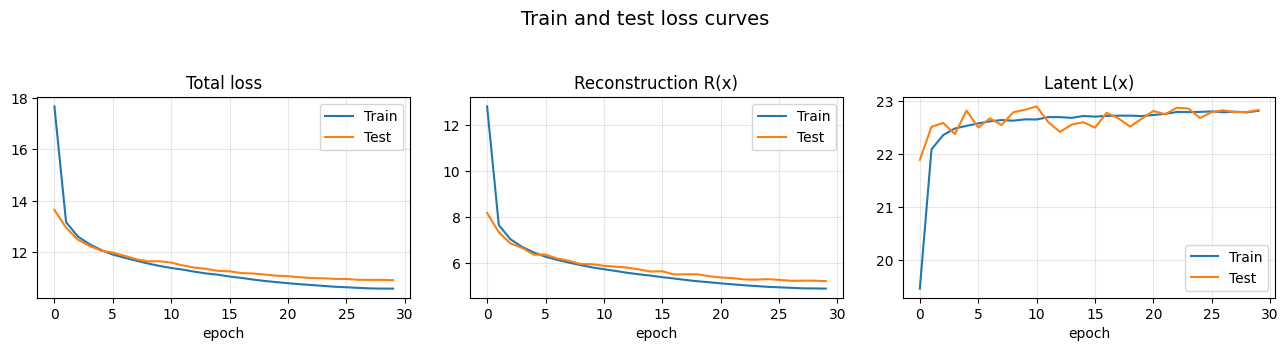

In [ ]:
# Loss curves visualization
plot_loss_curves(history, save_path="outputs/vae_loss_curves.png", show=True)

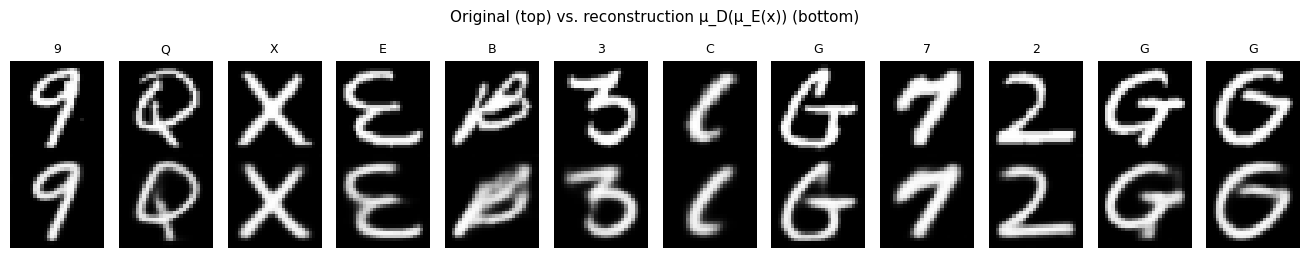

In [ ]:
# Reconstruction visualization
x_vis, y_vis = next(iter(test_dl))
plot_reconstructions(trained_model, x_vis, y_vis, save_path="outputs/vae_reconstructions.png", show=True)

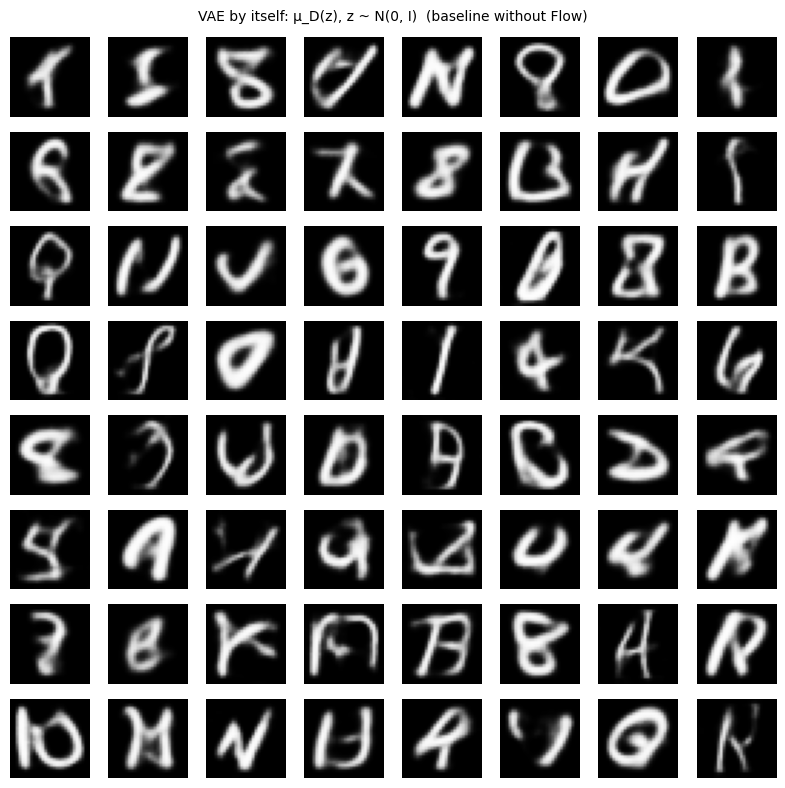

In [ ]:
# Visualize VAE generation (no flow)
plot_prior_samples(trained_model, save_path="outputs/vae_prior_samples.png", show=True)

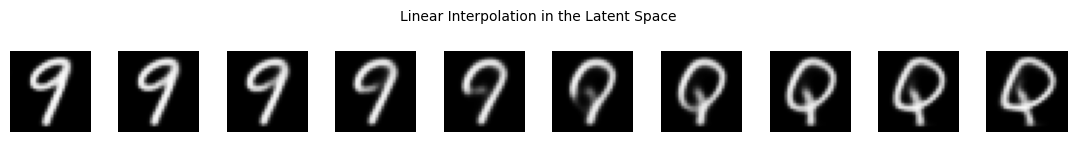

In [ ]:
# Viualize linear interpolation in the latent space
plot_interpolation(trained_model, x_vis[0], x_vis[1], y_vis[0].item(), y_vis[1].item(), save_path="outputs/vae_interpolation.png", show=True)

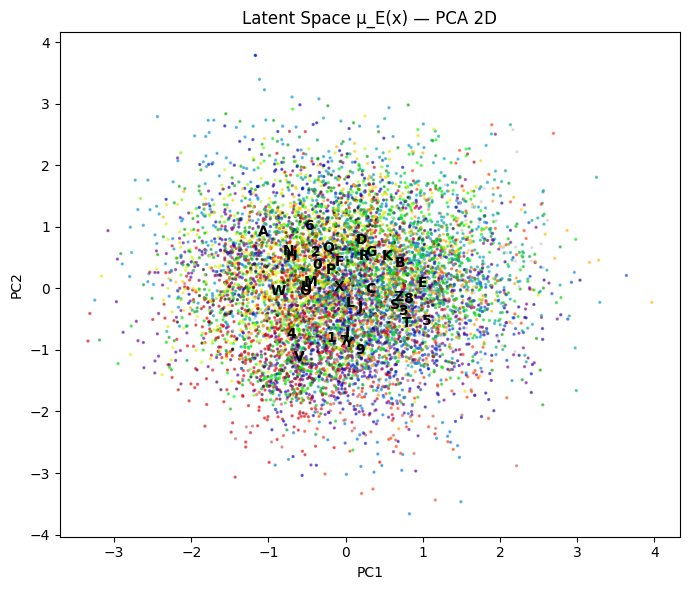

In [ ]:
# Visualize two principal components of the samples in latent space
plot_latent_pca(latents["test"]["mu"], latents["test"]["y"], save_path="outputs/vae_latent_pca.png", show=True)

## β parameter analysis

In [ ]:
latent_dim = 16
scalar_sigma = False
epochs = 10
batch_size = 256
lr = 1e-3
num_workers = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dl, test_dl = get_dataloaders()
models = []
metrics_list = []

RUN_SWEEP = True
if RUN_SWEEP:
    import json
    for b in [1.0, 0.5, 0.25, 0.05]:
        model = VAE(latent_dim, scalar_sigma).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        out_dir=f"outputs/beta_{b}"
        b_model, history, ckpt = train_vae(model, train_dl, test_dl, opt, sched, latent_dim, scalar_sigma, b, epochs, batch_size, lr, num_workers, device, out_dir=out_dir)
        metrics = encode_and_export_latents(b_model, train_dl, test_dl, ckpt, latent_dim, history, device, out_dir = out_dir, metrics_only = True)
        metrics_list.append({"beta": b, "metrics": metrics})
        models.append({"beta": b, "model": b_model})

Training latent_dim=16, epochs=10, lr=0.001
Device: cuda
Train: 86400 images | Test: 14400 images
VAE: m=16, sigma diagonal, beta=1.0, 2.41M parameters
[01/10] train: loss 27.70 (R 20.90, L 6.80) | test: loss 24.57 (R 16.06, L 8.51) | 14s
[02/10] train: loss 24.18 (R 15.43, L 8.74) | test: loss 23.82 (R 14.87, L 8.95) | 28s
[03/10] train: loss 23.62 (R 14.52, L 9.10) | test: loss 23.49 (R 14.23, L 9.26) | 43s
[04/10] train: loss 23.30 (R 13.99, L 9.31) | test: loss 23.31 (R 14.00, L 9.31) | 57s
[05/10] train: loss 23.09 (R 13.65, L 9.43) | test: loss 23.06 (R 13.60, L 9.46) | 71s
[06/10] train: loss 22.86 (R 13.31, L 9.55) | test: loss 22.87 (R 13.31, L 9.56) | 85s
[07/10] train: loss 22.69 (R 13.06, L 9.63) | test: loss 22.70 (R 12.96, L 9.75) | 99s
[08/10] train: loss 22.55 (R 12.85, L 9.71) | test: loss 22.58 (R 12.93, L 9.65) | 113s
[09/10] train: loss 22.43 (R 12.69, L 9.74) | test: loss 22.52 (R 12.79, L 9.73) | 127s
[10/10] train: loss 22.36 (R 12.61, L 9.75) | test: loss 22.46 

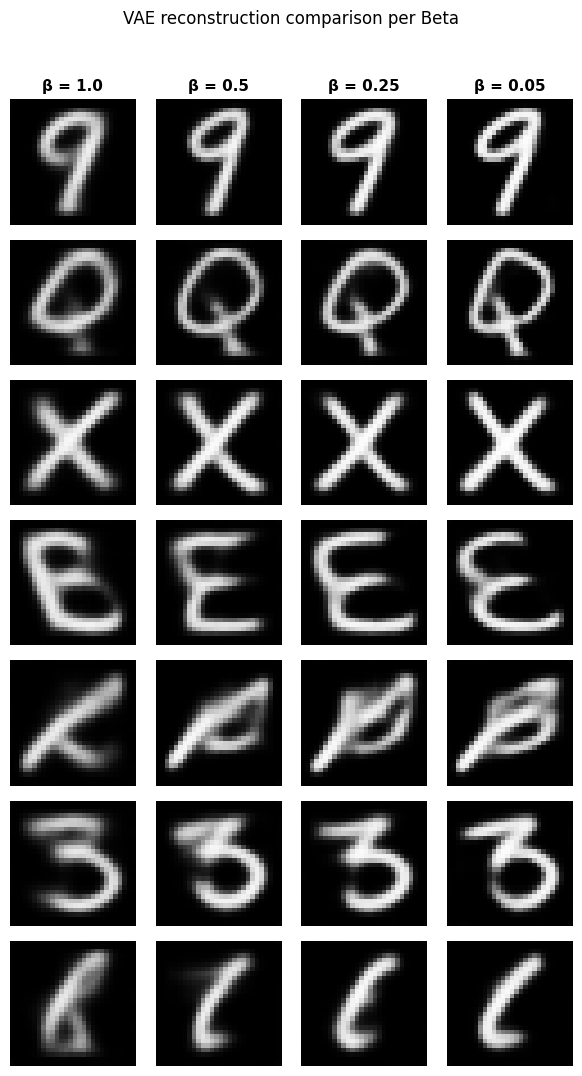

In [ ]:
x_vis, y_vis = next(iter(test_dl))
plot_reconstructions_by_beta(models, x_vis, save_path="outputs/reconstructions_by_beta", show=True)

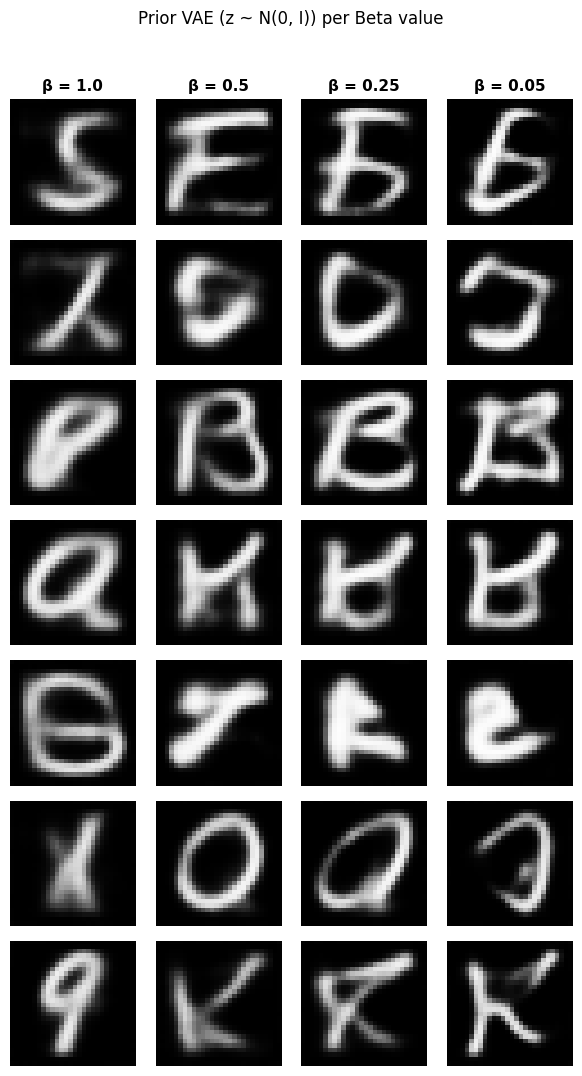

In [ ]:
plot_prior_samples_by_beta(models, seed=42, save_path="outputs/beta_generation_comparison", show=True)

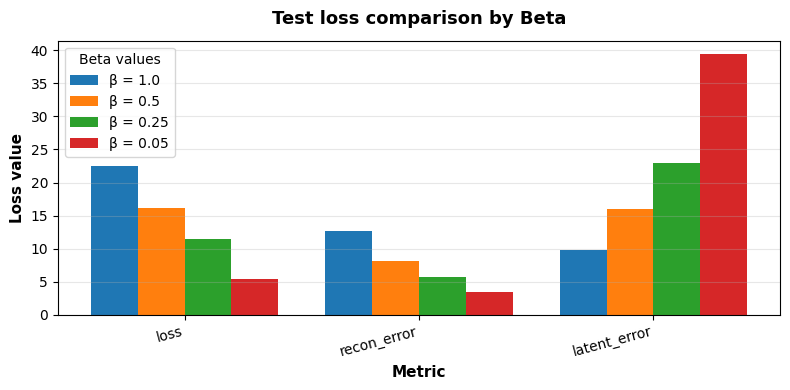

In [ ]:
plot_beta_test_metrics(metrics_list, save_path="outputs/betas_metrics_comparison.png")

## CVAE training

In [9]:
# PARAMETERS
latent_dim = 16
embed_dim = 16
scalar_sigma = False
beta = 0.25
epochs = 200
batch_size = 256
lr = 1e-3
num_workers = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out_dir="./cvae"

num_classes = len(CLASS_NAMES)
train_dl, test_dl = get_dataloaders()
model = CVAE(num_classes=num_classes, latent_dim=latent_dim, embed_dim=embed_dim, scalar_sigma=scalar_sigma).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

trained_model, history, ckpt = train_vae(model, train_dl, test_dl, opt, sched, latent_dim, scalar_sigma, beta, epochs, batch_size, lr, num_workers, device, out_dir=out_dir, conditional=True)

Training latent_dim=16, epochs=200, lr=0.001
Device: cuda
Train: 86400 images | Test: 14400 images
VAE: m=16, sigma diagonal, beta=0.25, 2.42M parameters
[01/200] train: loss 17.04 (R 12.70, L 17.38) | test: loss 13.02 (R 8.02, L 20.01) | 15s
[02/200] train: loss 12.41 (R 7.56, L 19.42) | test: loss 12.07 (R 7.30, L 19.05) | 29s
[03/200] train: loss 11.72 (R 6.92, L 19.21) | test: loss 11.56 (R 6.79, L 19.06) | 42s
[04/200] train: loss 11.32 (R 6.57, L 18.99) | test: loss 11.29 (R 6.55, L 18.99) | 55s
[05/200] train: loss 11.05 (R 6.35, L 18.81) | test: loss 10.98 (R 6.16, L 19.29) | 68s
[06/200] train: loss 10.83 (R 6.16, L 18.66) | test: loss 10.87 (R 6.22, L 18.59) | 81s
[07/200] train: loss 10.66 (R 6.02, L 18.55) | test: loss 10.69 (R 5.99, L 18.77) | 95s
[08/200] train: loss 10.51 (R 5.90, L 18.44) | test: loss 10.55 (R 5.99, L 18.26) | 108s
[09/200] train: loss 10.39 (R 5.80, L 18.36) | test: loss 10.48 (R 5.90, L 18.35) | 122s
[10/200] train: loss 10.29 (R 5.72, L 18.29) | test

In [10]:
latents = encode_and_export_latents(trained_model, train_dl, test_dl, ckpt, latent_dim, history, device, "cvae", conditional=True)

Latents saved in cvae/latents.pt: train (86400, 16), test (14400, 16)
Statistics of mu_E(x): mean -0.001, standard deviation 0.869, active dimensions 16/16
Metrics saved


## CVAE results visualization

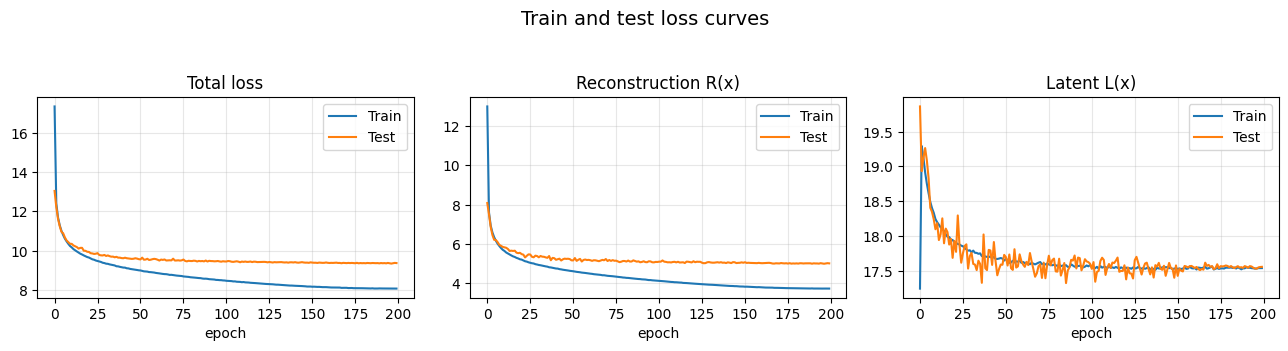

In [ ]:
# Loss curves visualization
plot_loss_curves(history, save_path="cvae/cvae_loss_curves.png", show=True)

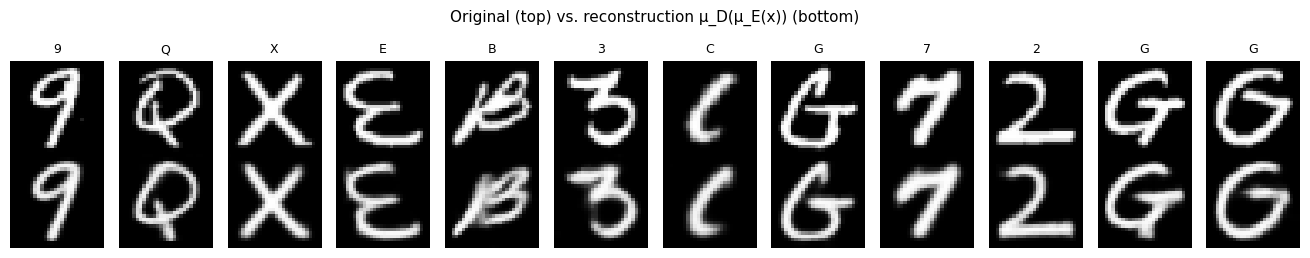

In [ ]:
x_vis, y_vis = next(iter(test_dl))
plot_reconstructions(trained_model, x_vis, y_vis, save_path="cvae/cvae_reconstructions.png", conditional=True, show=True)

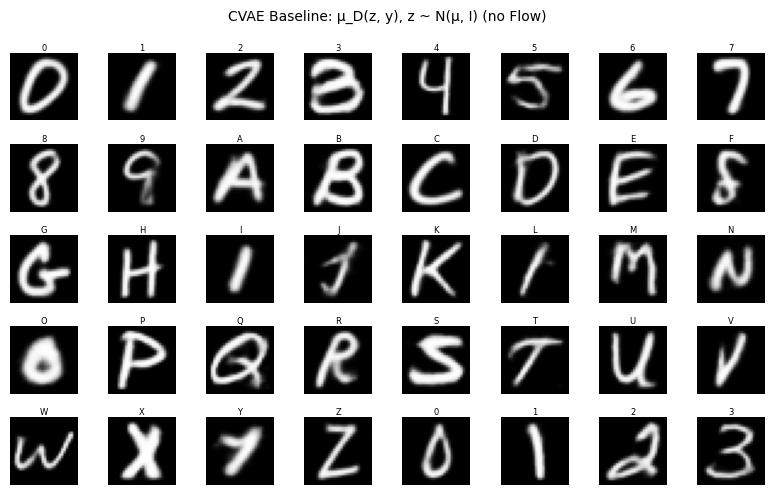

In [ ]:
plot_prior_samples_cvae(trained_model, 40, save_path="cvae/cvae_priors_with_label_signal.png", show=True)

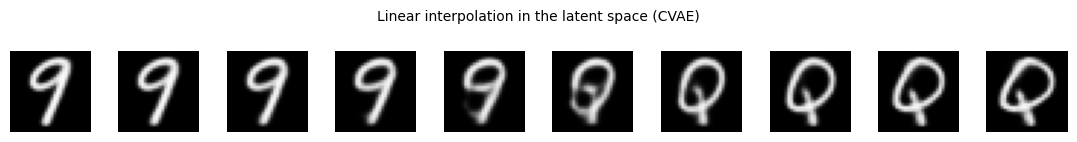

In [ ]:
plot_interpolation_cvae(trained_model, x_vis[0], x_vis[1], y_vis[0], y_vis[1], steps=10, save_path="cvae/interpolation_in_latent_space.png", show=True)

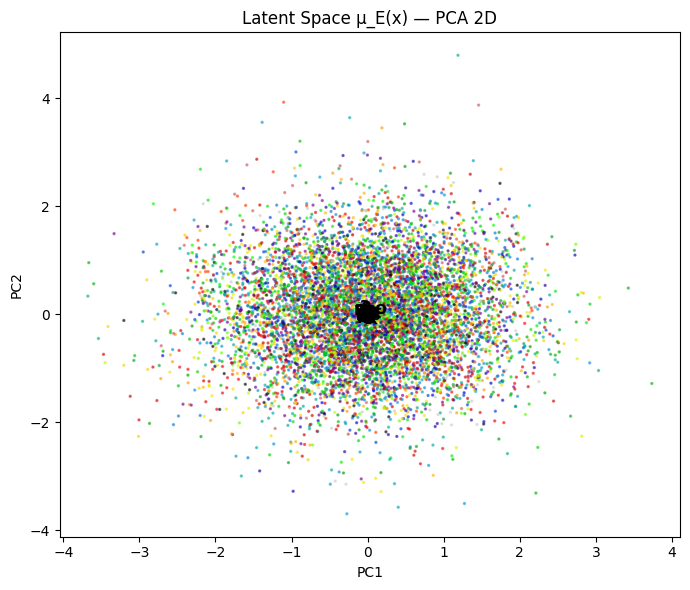

In [ ]:
plot_latent_pca(latents["test"]["mu"], latents["test"]["y"], save_path="cvae/cvae_latent_pca.png", show=True)

## Latent Flow

In [28]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class SinusoidalTimeEmbedding(nn.Module):
    """Maps scalar t in [0, 1] to a higher-dimensional frequency representation."""
    def __init__(self, dim: int = 32):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        t = t.view(-1, 1)
        half_dim = self.dim // 2
        freqs = torch.exp(
            -math.log(10000.0) * torch.arange(half_dim, device=t.device, dtype=t.dtype) / half_dim
        )
        args = t * freqs.unsqueeze(0)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class ResBlock1D(nn.Module):
    """Residual block for low-dimensional vector velocity fields."""
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.block(x)


class VelocityNet(nn.Module):
    """Parametrizes v_theta(x_tilde, t) for 16D inputs."""
    def __init__(self, data_dim: int = 16, time_dim: int = 32, hidden_dim: int = 128, num_blocks: int = 3):
        super().__init__()
        self.time_embed = SinusoidalTimeEmbedding(time_dim)
        self.in_proj = nn.Linear(data_dim + time_dim, hidden_dim)
        self.blocks = nn.ModuleList([ResBlock1D(hidden_dim) for _ in range(num_blocks)])
        self.out_proj = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, data_dim),
        )

    def forward(self, x_tilde: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_emb = self.time_embed(t)                          # (B, time_dim)
        h = torch.cat([x_tilde, t_emb], dim=-1)             # (B, data_dim + time_dim)
        h = self.in_proj(h)
        for block in self.blocks:
            h = block(h)
        return self.out_proj(h)                             # (B, data_dim)

class RectifiedFlow(nn.Module):
    def __init__(self, model: nn.Module, data_dim: int = 16):
        super().__init__()
        self.model = model
        self.data_dim = data_dim

    def compute_loss(
        self,
        x0: torch.Tensor,
        generator: torch.Generator | None = None,
        return_per_sample: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        batch_size = x0.shape[0]
        device = x0.device

        # 1. Sample t ~ Uniform(0, 1) and noise h ~ N(0, I)
        t = torch.rand((batch_size,), generator=generator, device=device, dtype=x0.dtype)
        h = torch.randn(x0.shape, generator=generator, device=device, dtype=x0.dtype)

        # 2. Straight-line interpolant: x_tilde = (1 - t) * x0 + t * h
        t_col = t.unsqueeze(-1)
        x_tilde = (1.0 - t_col) * x0 + t_col * h

        # 3. Predict velocity and compute MSE against (h - x0)
        v_pred = self.model(x_tilde, t)
        per_sample_mse = (v_pred - (h - x0)).pow(2).mean(dim=-1)  # (B,)

        if return_per_sample:
            return per_sample_mse, t
        return per_sample_mse.mean()

    @torch.no_grad()
    def sample(
        self,
        num_samples: int,
        num_steps: int = 50,
        method: str = "heun",
        device: torch.device | str = "cpu",
    ) -> torch.Tensor:
        """
        Integrates dx/dt = v_theta(x, t) backward from t = 1 (noise) to t = 0 (data).
        """
        self.model.eval()
        x = torch.randn(num_samples, self.data_dim, device=device)

        # Descending time grid: [1.0, ..., 0.0]
        ts = torch.linspace(1.0, 0.0, num_steps + 1, device=device)

        for i in range(num_steps):
            t_curr = ts[i]
            t_next = ts[i + 1]
            dt = t_curr - t_next  # positive step size: 1 / num_steps

            t_batch = torch.full((num_samples,), t_curr, device=device)
            v1 = self.model(x, t_batch)

            if method == "euler":
                # 1st-order backward step
                x = x - dt * v1

            elif method == "heun":
                # Predictor (Euler)
                x_pred = x - dt * v1
                # Corrector (evaluate velocity at predicted endpoint t_next)
                t_next_batch = torch.full((num_samples,), t_next, device=device)
                v2 = self.model(x_pred, t_next_batch)
                x = x - 0.5 * dt * (v1 + v2)

            else:
                raise ValueError(f"Unknown ODE solver '{method}'. Use 'euler' or 'heun'.")

        return x

In [33]:
from pathlib import Path
import copy
from tqdm import tqdm

def train_velocity_field(
    flow: RectifiedFlow,
    train_loader: DataLoader,
    val_loader: DataLoader | None = None,
    epochs: int = 80,
    optimizer: torch.optim.Optimizer | None = None,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    grad_clip: float = 1.0,
    device: torch.device | str = "cuda",
) -> dict[str, list[float]]:
    flow.to(device)
    if optimizer is None:
        optimizer = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    history = {"train_loss": [], "val_loss": [], "val_loss_low_t": []}
    best_val_loss = float("inf")
    best_weights = None

    for epoch in range(1, epochs + 1):
        # --- Train ---
        flow.train()
        running_loss, total_samples = 0.0, 0

        for batch in train_loader:
            x0 = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(device)
            loss = flow.compute_loss(x0)

            optimizer.zero_grad()
            loss.backward()
            if grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(flow.parameters(), max_norm=grad_clip)
            optimizer.step()

            running_loss += loss.item() * x0.shape[0]
            total_samples += x0.shape[0]

        scheduler.step()
        epoch_train_loss = running_loss / total_samples
        history["train_loss"].append(epoch_train_loss)

        # --- Validate ---
        if val_loader is not None:
            flow.eval()
            val_gen = torch.Generator(device=device).manual_seed(42)
            val_running, low_t_running = 0.0, 0.0
            val_samples, low_t_samples = 0, 0

            with torch.no_grad():
                for batch in val_loader:
                    x0 = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(device)
                    per_sample_mse, t = flow.compute_loss(
                        x0, generator=val_gen, return_per_sample=True
                    )

                    val_running += per_sample_mse.sum().item()
                    val_samples += x0.shape[0]

                    low_t_mask = t <= 0.2
                    if low_t_mask.any():
                        low_t_running += per_sample_mse[low_t_mask].sum().item()
                        low_t_samples += int(low_t_mask.sum().item())

            epoch_val_loss = val_running / val_samples
            epoch_low_t_loss = low_t_running / max(low_t_samples, 1)

            history["val_loss"].append(epoch_val_loss)
            history["val_loss_low_t"].append(epoch_low_t_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(flow.state_dict())

            if epoch % 10 == 0 or epoch == 1:
                print(
                    f"Epoch {epoch:03d}/{epochs:03d} | "
                    f"Train MSE: {epoch_train_loss:.5f} | "
                    f"Val MSE: {epoch_val_loss:.5f} | "
                    f"Val MSE (t<=0.2): {epoch_low_t_loss:.5f}"
                )
        elif epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:03d}/{epochs:03d} | Train MSE: {epoch_train_loss:.5f}")

    if best_weights is not None:
        flow.load_state_dict(best_weights)

    return history

def save_flow_checkpoint(
    flow: RectifiedFlow,
    save_path: str,
    config: dict | None = None,
    history: dict | None = None,
) -> None:
    out_file = Path(save_path)
    out_file.parent.mkdir(parents=True, exist_ok=True)

    checkpoint = {
        "state_dict": flow.state_dict(),
        "data_dim": flow.data_dim,
        "config": config or {},
        "history": history,
    }
    torch.save(checkpoint, out_file)


def load_flow_checkpoint(
    checkpoint_path: str,
    device: torch.device | str = "cuda",
) -> tuple[RectifiedFlow, dict]:
    ckpt = torch.load(checkpoint_path, map_location=device, weights_only=True)
    cfg = ckpt.get("config", {})

    model = VelocityNet(
        data_dim=ckpt.get("data_dim", 16),
        time_dim=cfg.get("time_dim", 32),
        hidden_dim=cfg.get("hidden_dim", 128),
        num_blocks=cfg.get("num_blocks", 2),
    )
    flow = RectifiedFlow(model=model, data_dim=ckpt.get("data_dim", 16))
    flow.load_state_dict(ckpt["state_dict"])
    flow.to(device).eval()

    return flow, ckpt

In [16]:
import torch
from torch.utils.data import DataLoader, TensorDataset


def get_latent_dataloaders(
    latents_path: str,
    batch_size: int = 256,
    test_batch_size: int = 512,
) -> tuple[DataLoader, DataLoader]:
    data = torch.load(latents_path, map_location="cpu")

    train_dict = data["train"]
    test_dict = data["test"]

    train_dataset = TensorDataset(
        train_dict["mu"].float(),
        train_dict["y"].long(),
    )
    test_dataset = TensorDataset(
        test_dict["mu"].float(),
        test_dict["y"].long(),
    )

    use_pin_memory = torch.cuda.is_available()

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=use_pin_memory,
        drop_last=True,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=test_batch_size,
        shuffle=False,
        pin_memory=use_pin_memory,
    )

    return train_loader, test_loader

In [29]:
# FLOW PARAMETERS
latent_dim = 16
epochs = 200
batch_size = 256
lr = 1e-3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = VelocityNet(data_dim=latent_dim, time_dim=32, hidden_dim=128, num_blocks=3).to(device)
flow = RectifiedFlow(model=model, data_dim=latent_dim)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
train_loader, test_loader = get_latent_dataloaders("./cvae/latents.pt")

history = train_velocity_field(flow, train_loader, test_loader, epochs, optimizer, lr, device=device)

Epoch 001/200 | Train MSE: 1.48514 | Val MSE: 1.38743 | Val MSE (t<=0.2): 1.30498
Epoch 010/200 | Train MSE: 1.35285 | Val MSE: 1.35182 | Val MSE (t<=0.2): 1.23714
Epoch 020/200 | Train MSE: 1.33935 | Val MSE: 1.34228 | Val MSE (t<=0.2): 1.22778
Epoch 030/200 | Train MSE: 1.33719 | Val MSE: 1.33844 | Val MSE (t<=0.2): 1.21742
Epoch 040/200 | Train MSE: 1.33648 | Val MSE: 1.33488 | Val MSE (t<=0.2): 1.21155
Epoch 050/200 | Train MSE: 1.33050 | Val MSE: 1.33249 | Val MSE (t<=0.2): 1.21099
Epoch 060/200 | Train MSE: 1.33042 | Val MSE: 1.33146 | Val MSE (t<=0.2): 1.20648
Epoch 070/200 | Train MSE: 1.32759 | Val MSE: 1.32944 | Val MSE (t<=0.2): 1.20606
Epoch 080/200 | Train MSE: 1.32539 | Val MSE: 1.32911 | Val MSE (t<=0.2): 1.20402
Epoch 090/200 | Train MSE: 1.32900 | Val MSE: 1.32853 | Val MSE (t<=0.2): 1.20368
Epoch 100/200 | Train MSE: 1.32764 | Val MSE: 1.32782 | Val MSE (t<=0.2): 1.20251
Epoch 110/200 | Train MSE: 1.32756 | Val MSE: 1.32638 | Val MSE (t<=0.2): 1.19941
Epoch 120/200 | 

In [35]:
save_flow_checkpoint(flow, save_path="./flow/flow_model.pt")

In [36]:
# Generate samples with Euler vs. Heun
samples_euler = flow.sample(num_samples=64, num_steps=50, method="euler", device=device)
samples_heun = flow.sample(num_samples=64, num_steps=25, method="heun", device=device)
print(f"Euler shape: {samples_euler.shape} | Heun shape: {samples_heun.shape}")

Euler shape: torch.Size([64, 16]) | Heun shape: torch.Size([64, 16])


## Velocity field model loss curves visualization

In [37]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def plot_loss_history(
    history: dict[str, list[float]],
    save_path: str = "flow_loss_history.png",
    title: str = "Rectified Flow Training & Test Loss",
    show: bool = True,
) -> plt.Figure:
    train_loss = history.get("train_loss", [])
    val_loss = history.get("val_loss", [])
    low_t_loss = history.get("val_loss_low_t", [])

    epochs = np.arange(1, len(train_loss) + 1)
    has_low_t = len(low_t_loss) > 0

    ncols = 2 if has_low_t else 1
    fig, axes = plt.subplots(1, ncols, figsize=(6.5 * ncols, 4.5), constrained_layout=True)
    if ncols == 1:
        axes = [axes]

    ax = axes[0]
    ax.plot(epochs, train_loss, label="Train MSE", linewidth=2.0, color="#1f77b4")

    if len(val_loss) > 0:
        ax.plot(epochs, val_loss, label="Test MSE", linewidth=2.0, color="#ff7f0e")
        best_idx = int(np.argmin(val_loss))
        ax.axvline(
            epochs[best_idx],
            color="#ff7f0e",
            linestyle="--",
            alpha=0.6,
            label=f"Best Test (ep {epochs[best_idx]}: {val_loss[best_idx]:.4f})",
        )

    ax.set_title("Overall Velocity MSE")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(frameon=True)

    if has_low_t:
        ax_low = axes[1]
        ax_low.plot(
            epochs,
            low_t_loss,
            label="Test MSE (t <= 0.2)",
            linewidth=2.0,
            color="#2ca02c",
        )
        best_low_idx = int(np.argmin(low_t_loss))
        ax_low.scatter(
            epochs[best_low_idx],
            low_t_loss[best_low_idx],
            color="#2ca02c",
            zorder=5,
            label=f"Min (ep {epochs[best_low_idx]}: {low_t_loss[best_low_idx]:.4f})",
        )
        ax_low.set_title("Low-Noise Regime MSE (t <= 0.2)")
        ax_low.set_xlabel("Epoch")
        ax_low.set_ylabel("MSE Loss")
        ax_low.grid(True, linestyle=":", alpha=0.5)
        ax_low.legend(frameon=True)

    fig.suptitle(title, fontsize=13)

    out_file = Path(save_path)
    out_file.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_file, dpi=300, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig

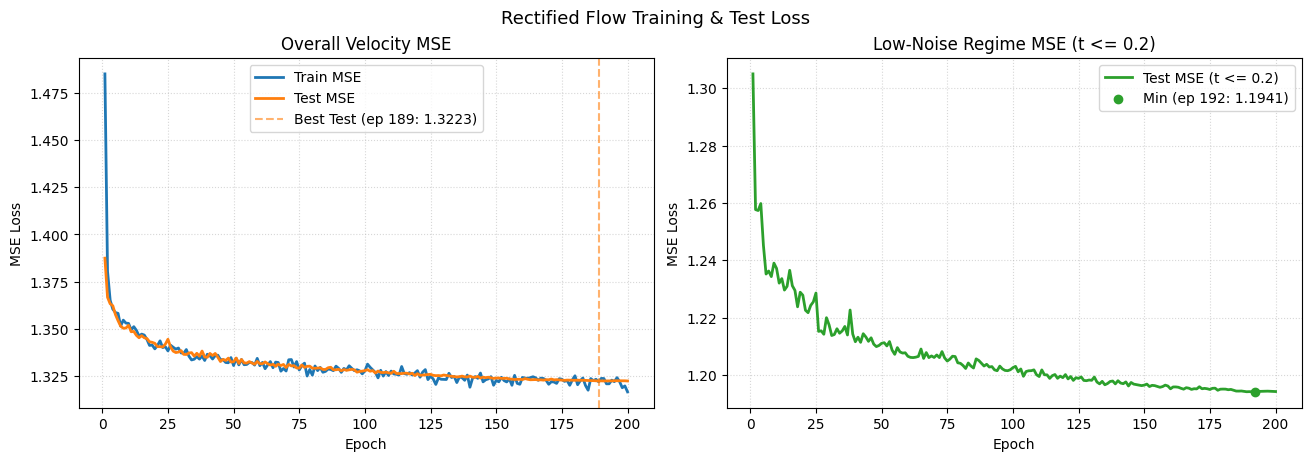

In [39]:
plot_loss_history(history, save_path="./flow/loss_curves.png", show=True)

## Visualization of velocity field during generation (2 principal components of the latent space)

In [46]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from IPython.display import display


@torch.no_grad()
def plot_velocity_fields(
    flow,
    real_data: torch.Tensor,
    plot_times: list[float] = [1.0, 0.75, 0.5, 0.25, 0.05],
    num_samples: int = 80,
    num_steps: int = 40,
    method: str = "heun",
    grid_res: int = 20,
    save_path: str = None,
    device: torch.device | str = "cuda",
):
    """
    Visualizes the 16D learned velocity field -v_theta(x, t) and particle trajectories
    projected onto the top 2 principal components of `real_data` at chosen timesteps.
    """
    flow.eval()
    flow.to(device)

    # 1. Fit 2D PCA on real 16D data to define the viewing plane
    real_np = real_data.detach().cpu().numpy()
    pca = PCA(n_components=2)
    real_2d = pca.fit_transform(real_np)

    # Build a 2D grid covering the real data + initial Gaussian noise range
    bound = max(np.abs(real_2d).max() * 1.3, 3.0)
    lin = np.linspace(-bound, bound, grid_res)
    xx, yy = np.meshgrid(lin, lin)
    grid_2d = np.column_stack([xx.ravel(), yy.ravel()])          # (G^2, 2)

    # Lift 2D grid points back to 16D (PCs 3..16 set to 0)
    grid_16d = torch.tensor(
        pca.inverse_transform(grid_2d), dtype=torch.float32, device=device
    )

    # 2. Run ODE sampling and store particle positions at every step
    x = torch.randn(num_samples, flow.data_dim, device=device)
    ts = torch.linspace(1.0, 0.0, num_steps + 1, device=device)
    trajectory = [x.cpu().numpy()]

    for i in range(num_steps):
        t_curr, t_next = ts[i], ts[i + 1]
        dt = t_curr - t_next

        v1 = flow.model(x, torch.full((num_samples,), t_curr, device=device))
        if method == "euler":
            x = x - dt * v1
        elif method == "heun":
            x_pred = x - dt * v1
            v2 = flow.model(x_pred, torch.full((num_samples,), t_next, device=device))
            x = x - 0.5 * dt * (v1 + v2)
        else:
            raise ValueError(f"Unknown solver '{method}'. Use 'euler' or 'heun'.")

        trajectory.append(x.cpu().numpy())

    # Project full trajectories (steps + 1, num_samples, 16) -> (steps + 1, num_samples, 2)
    traj_2d = np.stack([pca.transform(step_x) for step_x in trajectory], axis=0)

    # 3. Plot each requested snapshot
    fig, axes = plt.subplots(1, len(plot_times), figsize=(4.5 * len(plot_times), 4.5), sharex=True, sharey=True)
    if len(plot_times) == 1:
        axes = [axes]

    for ax, target_t in zip(axes, plot_times):
        # Match the closest discrete solver timestep
        step_idx = int(torch.argmin(torch.abs(ts - target_t)).item())
        t_val = float(ts[step_idx].item())

        # Evaluate velocity field on the 2D slice (negated for sampling direction t: 1 -> 0)
        t_grid = torch.full((grid_16d.shape[0],), t_val, device=device)
        v_16d = -flow.model(grid_16d, t_grid).cpu().numpy()

        # Project displacement vectors without mean subtraction
        v_2d = v_16d @ pca.components_.T
        u = v_2d[:, 0].reshape(grid_res, grid_res)
        w = v_2d[:, 1].reshape(grid_res, grid_res)
        speed = np.hypot(u, w)

        # Background: real data distribution
        ax.scatter(real_2d[:, 0], real_2d[:, 1], s=6, alpha=0.15, color="gray", label="Real data")

        # Vector field arrows
        q = ax.quiver(xx, yy, u, w, speed, cmap="viridis", alpha=0.85, pivot="mid")

        # Particle trails up to step_idx + current particle positions
        if step_idx > 0:
            for p in range(min(num_samples, 25)):
                ax.plot(
                    traj_2d[: step_idx + 1, p, 0],
                    traj_2d[: step_idx + 1, p, 1],
                    color="crimson",
                    alpha=0.25,
                    linewidth=0.9,
                )
        ax.scatter(
            traj_2d[step_idx, :, 0],
            traj_2d[step_idx, :, 1],
            s=18,
            color="crimson",
            edgecolors="white",
            linewidths=0.4,
            label="Samples",
        )

        ax.set_title(f"t = {t_val:.2f}")
        ax.set_xlabel("PC 1")
        ax.set_xlim(-bound, bound)
        ax.set_ylim(-bound, bound)

    axes[0].set_ylabel("PC 2")
    axes[0].legend(loc="upper right", frameon=True, fontsize=8)
    fig.colorbar(q, ax=axes, fraction=0.015, pad=0.02, label="Velocity magnitude ||v||")
    fig.suptitle(f"Learned Reverse Velocity Field & Trajectories ({method.upper()})", y=1.03)
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    display(fig)
    plt.close(fig)
    return fig

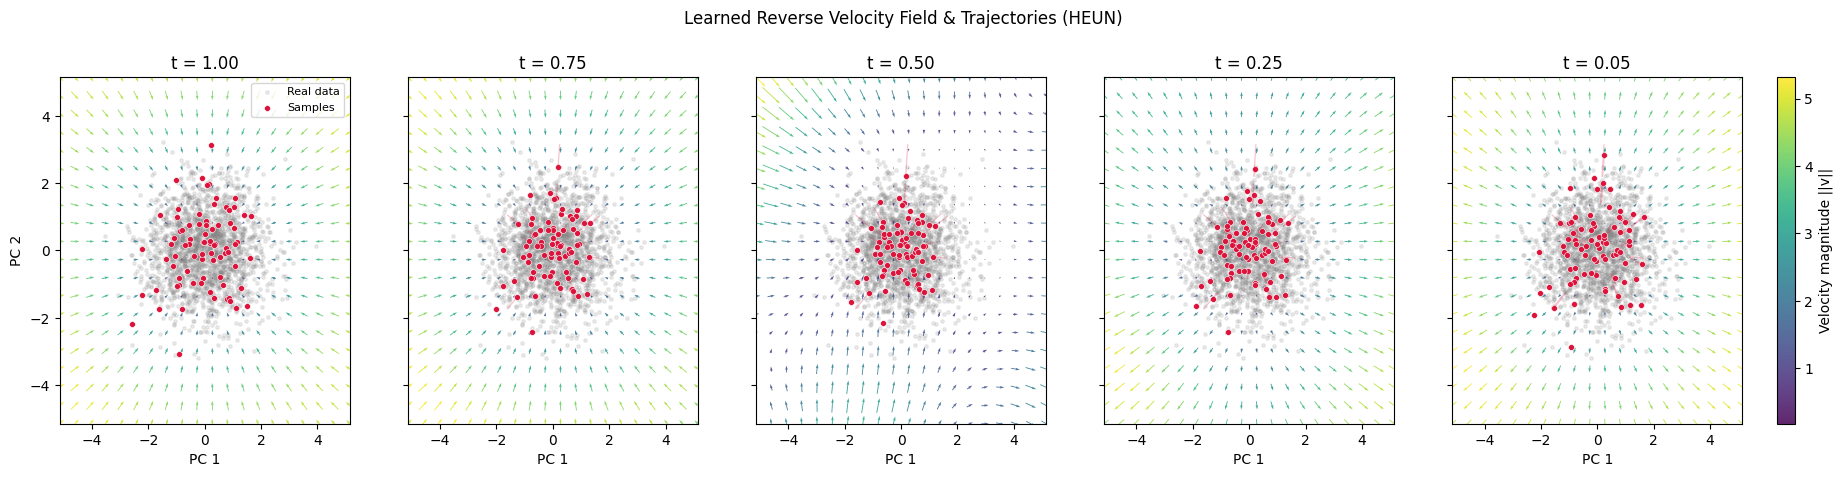

In [48]:
real_data = test_loader.dataset.tensors[0]

fig = plot_velocity_fields(
    flow=flow,
    real_data=real_data[:2000],
    plot_times=[1.0, 0.75, 0.5, 0.25, 0.05],
    num_samples=80,
    num_steps=40,
    method="heun",
    grid_res=20,
    save_path="./flow/flow_visualization",
    device=device,
)

## Full generation (latent flow + conditional decoder)

In [54]:
@torch.no_grad()
def generate_data_samples(cvae: CVAE, flow: RectifiedFlow, n: int = 64, seed: int = 0, save_path=None, y=None, show=True):
    cvae.eval()
    flow.eval()
    device = next(cvae.parameters()).device
    g = torch.Generator(device="cpu").manual_seed(seed)

    labels_list = []
    if y is None:
        for i in range(n):
            labels_list.append(i % cvae.num_classes)
    else:
        y = char_to_idx[y]
        for i in range(n):
            labels_list.append(int(y))

    y = torch.tensor(labels_list, dtype=torch.long, device=device)
    z = flow.sample(num_samples=n, num_steps=50, method="heun", device=device)

    imgs = cvae.decode(z, y).cpu()

    cols = 8
    fig, axes = plt.subplots(n // cols, cols, figsize=(cols * 1.0, n // cols * 1.0))
    for i, (ax, img) in enumerate(zip(axes.flat, imgs)):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        # Optional: display the class name or index as a tiny title
        cls_idx = int(y[i].item())
        ax.set_title(idx_to_char[cls_idx], fontsize=6, pad=1)

    fig.suptitle("CVAE with Rectified Flow in Latent Space", fontsize=10)
    _finish(fig, save_path, show)

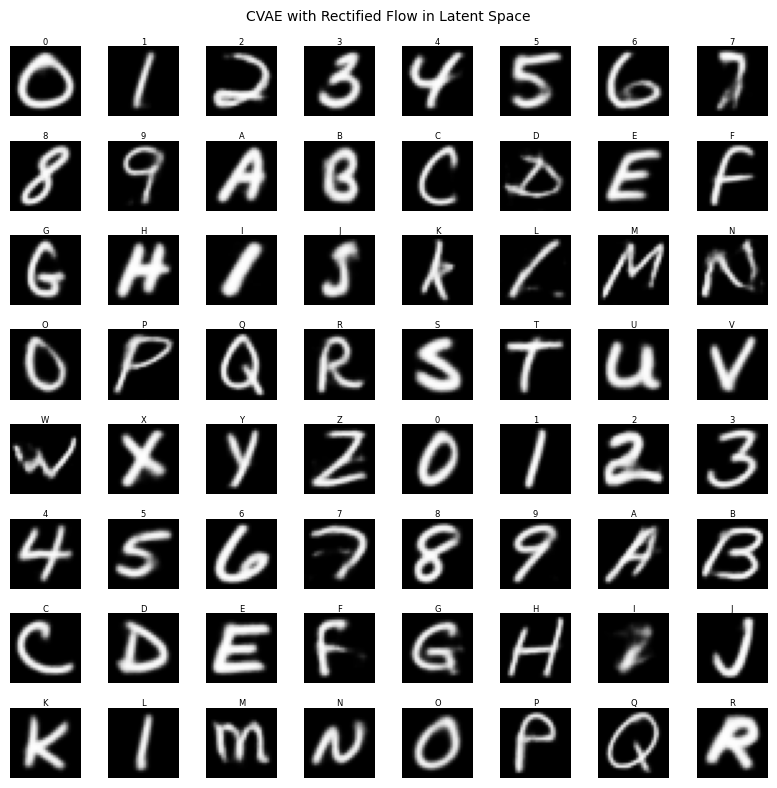

In [52]:
generate_data_samples(trained_model, flow, n=64, seed=42, save_path="./flow/final_samples.png", show=True)

## Bonus (+5): Conditional Latent Flow + Classifier-Free Guidance

So far, class control came from the **CVAE decoder**, while the velocity field $\Phi(z, t)$ was unconditional.
The assignment bonus (Part 7) asks for the conditioning signal **inside the flow**, $\Phi(z, t, c)$, plus
**Classifier-Free Guidance (CFG)** at sampling time.

**Setup.** We use the latents of the **unconditional VAE** (`outputs/latents.pt`): here the class information
lives in $z$ itself, so the flow must learn to steer each sample to the right class region.
In this section we follow the course convention (forward parametrization):

- $z(0) \sim \mathcal{N}(0, I)$ (noise), $\; z(1) = \mu_E(x)$ (data, standardized per dimension)
- $z(t) = (1-t)\,z(0) + t\,z(1)$, target velocity $z(1) - z(0)$
- $c \in \{0, \dots, 35\}$, plus a **null token** $\varnothing = 36$

**Training (label dropout).** With probability $p_{\text{uncond}} = 0.15$ the label is replaced by $\varnothing$, so a single
network learns both $\Phi(z, t, c)$ and $\Phi(z, t, \varnothing)$:
$$\min_\theta \; \mathbb{E}\,\big\| \Phi(z(t), t, \tilde c;\theta) - (z(1) - z(0)) \big\|^2$$

**Sampling (CFG).** Integrate $dz/dt = v_{\text{CFG}}$ from $t=0$ to $t=1$ (Euler or Heun), with
$$v_{\text{CFG}}(z, t, c) = \Phi(z, t, \varnothing) + w \,\big(\Phi(z, t, c) - \Phi(z, t, \varnothing)\big)$$
$w = 0$ is unconditional, $w = 1$ is plain conditional, $w > 1$ pushes harder towards class $c$.
Finally $x = \mu_D(z(1))$ with the VAE decoder.

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class CondSinusoidalEmbedding(nn.Module):
    # Sinusoidal embedding for t in [0, 1]
    def __init__(self, dim: int = 128):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
        args = 1000.0 * t.float()[:, None] * freqs[None, :]
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class AdaLNBlock(nn.Module):
    # Residual MLP block modulated (scale/shift/gate) by the (time + class) embedding
    def __init__(self, hidden_dim: int, cond_dim: int):
        super().__init__()
        self.norm = nn.LayerNorm(hidden_dim, elementwise_affine=False)
        self.fc1 = nn.Linear(hidden_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.mod = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 3 * hidden_dim))
        nn.init.zeros_(self.mod[-1].weight)  # starts as identity (adaLN-zero)
        nn.init.zeros_(self.mod[-1].bias)

    def forward(self, h: torch.Tensor, cond: torch.Tensor) -> torch.Tensor:
        scale, shift, gate = self.mod(cond).chunk(3, dim=-1)
        u = self.norm(h) * (1 + scale) + shift
        u = self.fc2(F.silu(self.fc1(F.silu(u))))
        return h + gate * u


class ConditionalVelocityNet(nn.Module):
    # Phi(z, t, c): velocity field conditioned on the class c (36 classes + null token)
    def __init__(self, latent_dim: int = 16, hidden_dim: int = 256, cond_dim: int = 128,
                 num_blocks: int = 4, num_classes: int = 36):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.null_class = num_classes  # index of the null token (unconditional)
        self.time_mlp = nn.Sequential(CondSinusoidalEmbedding(cond_dim), nn.Linear(cond_dim, cond_dim),
                                      nn.SiLU(), nn.Linear(cond_dim, cond_dim))
        self.class_emb = nn.Embedding(num_classes + 1, cond_dim)
        self.in_proj = nn.Linear(latent_dim, hidden_dim)
        self.blocks = nn.ModuleList([AdaLNBlock(hidden_dim, cond_dim) for _ in range(num_blocks)])
        self.out = nn.Sequential(nn.LayerNorm(hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, latent_dim))

    def forward(self, z: torch.Tensor, t: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        cond = self.time_mlp(t) + self.class_emb(c)
        h = self.in_proj(z)
        for block in self.blocks:
            h = block(h, cond)
        return self.out(h)


class CFGRectifiedFlow(nn.Module):
    # Rectified Flow in latent space (t=0 noise -> t=1 data) with Classifier-Free Guidance
    def __init__(self, net: ConditionalVelocityNet, mu_mean: torch.Tensor, mu_std: torch.Tensor):
        super().__init__()
        self.net = net
        self.latent_dim = net.latent_dim
        self.null_class = net.null_class
        # standardization of the latents (z_norm = (mu - mean) / std)
        self.register_buffer("mu_mean", mu_mean.float().clone())
        self.register_buffer("mu_std", mu_std.float().clamp_min(1e-3).clone())

    def normalize(self, mu):
        return (mu - self.mu_mean) / self.mu_std

    def denormalize(self, z):
        return z * self.mu_std + self.mu_mean

    def compute_loss(self, mu: torch.Tensor, y: torch.Tensor, p_uncond: float = 0.15) -> torch.Tensor:
        z1 = self.normalize(mu)                      # data,  t = 1
        z0 = torch.randn_like(z1)                    # noise, t = 0
        t = torch.rand(z1.shape[0], device=z1.device)
        zt = (1 - t[:, None]) * z0 + t[:, None] * z1
        drop = torch.rand(y.shape[0], device=y.device) < p_uncond
        c = torch.where(drop, torch.full_like(y, self.null_class), y)   # label dropout
        return F.mse_loss(self.net(zt, t, c), z1 - z0)

    @torch.no_grad()
    def velocity(self, z, t, c, w: float):
        # v_CFG = Phi(z,t,null) + w * (Phi(z,t,c) - Phi(z,t,null))
        null = torch.full_like(c, self.null_class)
        if w == 0.0:
            return self.net(z, t, null)
        if w == 1.0:
            return self.net(z, t, c)
        v = self.net(torch.cat([z, z]), torch.cat([t, t]), torch.cat([c, null]))
        v_cond, v_uncond = v.chunk(2)
        return v_uncond + w * (v_cond - v_uncond)

    @torch.no_grad()
    def sample(self, labels: torch.Tensor, w: float = 3.0, num_steps: int = 25, method: str = "heun",
               z0: torch.Tensor | None = None, return_trajectory: bool = False):
        # Integrates dz/dt = v_CFG from t=0 to t=1; returns mu_E-scale latents ready for the decoder
        self.net.eval()
        device = self.mu_mean.device
        c = labels.to(device).long()
        z = torch.randn(len(c), self.latent_dim, device=device) if z0 is None else z0.to(device).clone()
        traj = [z.cpu()]
        dt = 1.0 / num_steps
        for i in range(num_steps):
            t = torch.full((len(c),), i * dt, device=device)
            v1 = self.velocity(z, t, c, w)
            if method == "euler":
                z = z + dt * v1
            elif method == "heun":
                z_pred = z + dt * v1
                v2 = self.velocity(z_pred, t + dt, c, w)
                z = z + 0.5 * dt * (v1 + v2)
            else:
                raise ValueError(f"Unknown method '{method}' (use 'euler' or 'heun')")
            if return_trajectory:
                traj.append(z.cpu())
        out = self.denormalize(z)
        return (out, traj) if return_trajectory else out

In [ ]:
import copy
import time
from pathlib import Path


def train_cfg_flow(flow, train_loader, test_loader, epochs=100, lr=1e-3, p_uncond=0.15,
                   ema_decay=0.999, device="cpu"):
    # Trains Phi(z, t, c) with label dropout; keeps an EMA copy of the weights (used for sampling)
    opt = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(train_loader))
    ema = copy.deepcopy(flow).eval()
    history = {"train_loss": [], "test_loss": []}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        flow.train()
        tot, n = 0.0, 0
        for mu, y in train_loader:
            mu, y = mu.to(device), y.to(device)
            loss = flow.compute_loss(mu, y, p_uncond)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(flow.parameters(), 1.0)
            opt.step()
            sched.step()
            with torch.no_grad():
                for pe, p in zip(ema.parameters(), flow.parameters()):
                    pe.lerp_(p, 1 - ema_decay)
            tot += loss.item() * len(mu)
            n += len(mu)
        # test loss (fixed seed so epochs are comparable)
        ema.eval()
        g_state = torch.random.get_rng_state()
        torch.manual_seed(0)
        with torch.no_grad():
            te, m = 0.0, 0
            for mu, y in test_loader:
                mu, y = mu.to(device), y.to(device)
                te += ema.compute_loss(mu, y, p_uncond).item() * len(mu)
                m += len(mu)
        torch.random.set_rng_state(g_state)
        history["train_loss"].append(tot / n)
        history["test_loss"].append(te / m)
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f"[{epoch:03d}/{epochs}] train {tot / n:.4f} | test (EMA) {te / m:.4f} | {time.time() - t0:.0f}s")
    return ema, history


def save_cfg_flow(flow, path, config, history):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": flow.state_dict(), "config": config, "history": history}, path)


def load_cfg_flow(path, device="cpu"):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    cfg = ckpt["config"]
    net = ConditionalVelocityNet(**cfg)
    flow = CFGRectifiedFlow(net, torch.zeros(cfg["latent_dim"]), torch.ones(cfg["latent_dim"]))
    flow.load_state_dict(ckpt["state_dict"])
    return flow.to(device).eval(), ckpt

In [ ]:
# CFG FLOW PARAMETERS
cfg_config = dict(latent_dim=16, hidden_dim=256, cond_dim=128, num_blocks=4, num_classes=36)
cfg_epochs = 100        # ~5 min on a Colab T4
cfg_batch_size = 512
cfg_lr = 1e-3
p_uncond = 0.15
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

# Unconditional VAE latents (exported in the "VAE training" section) + the VAE itself as decoder
vae_latents = torch.load("outputs/latents.pt", map_location="cpu", weights_only=False)
vae = load_vae("outputs/vae.pt", device=device)
cfg_train_loader, cfg_test_loader = get_latent_dataloaders("outputs/latents.pt", batch_size=cfg_batch_size)

cfg_flow = CFGRectifiedFlow(ConditionalVelocityNet(**cfg_config),
                            vae_latents["mu_mean"], vae_latents["mu_std"]).to(device)
print(f"Phi(z, t, c): {sum(p.numel() for p in cfg_flow.parameters()) / 1e6:.2f}M parameters")

cfg_flow, cfg_history = train_cfg_flow(cfg_flow, cfg_train_loader, cfg_test_loader, epochs=cfg_epochs,
                                       lr=cfg_lr, p_uncond=p_uncond, device=device)
save_cfg_flow(cfg_flow, "cfg_flow/cfg_flow.pt", cfg_config, cfg_history)

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(cfg_history["train_loss"], label="train")
ax.plot(cfg_history["test_loss"], label="test (EMA)")
ax.set_xlabel("epoch")
ax.set_ylabel("flow matching MSE")
ax.set_title("Conditional velocity field $\\Phi(z,t,c)$")
ax.legend()
_finish(fig, "cfg_flow/cfg_loss_curves.png", show=True)

### All 36 classes with CFG
Each row is one class; every column starts from a different noise $z(0)$. Heun, 25 steps, $w = 3$.

In [ ]:
@torch.no_grad()
def generate_cfg(labels, w=3.0, num_steps=25, method="heun", z0=None):
    z1 = cfg_flow.sample(labels, w=w, num_steps=num_steps, method=method, z0=z0)
    return vae.decode(z1).cpu()


def plot_class_grid(w=3.0, per_class=10, seed=0, save_path=None, show=True):
    g = torch.Generator().manual_seed(seed)
    labels = torch.arange(36).repeat_interleave(per_class)
    z0 = torch.randn(len(labels), cfg_config["latent_dim"], generator=g)
    imgs = generate_cfg(labels, w=w, z0=z0)
    # 36 rows x per_class columns, split in two panels of 18 classes for readability
    fig, axes = plt.subplots(18, 2 * per_class + 1, figsize=((2 * per_class + 1) * 0.55, 18 * 0.6))
    for ax in axes.flat:
        ax.axis("off")
    for cls in range(36):
        row, block = cls % 18, cls // 18
        for j in range(per_class):
            col = block * (per_class + 1) + j
            axes[row, col].imshow(imgs[cls * per_class + j, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, block * (per_class + 1)].set_title(CLASS_NAMES[cls], fontsize=8, loc="left", pad=1)
    fig.suptitle(f"Conditional latent flow + CFG (w = {w})", fontsize=11)
    _finish(fig, save_path, show)


plot_class_grid(w=3.0, save_path="cfg_flow/cfg_all_classes_w3.png")

### Effect of the guidance scale $w$
Same initial noise $z(0)$ for every column; only $w$ changes. $w=0$ ignores the label (unconditional sample),
$w=1$ is the plain conditional field, larger $w$ gives more class-typical (and less diverse) characters.

In [ ]:
def plot_guidance_sweep(chars="0A7GKR", ws=(0.0, 1.0, 2.0, 3.0, 5.0), per_char=4, seed=1,
                        save_path=None, show=True):
    g = torch.Generator().manual_seed(seed)
    labels = torch.tensor([CLASS_NAMES.index(ch) for ch in chars]).repeat_interleave(per_char)
    z0 = torch.randn(len(labels), cfg_config["latent_dim"], generator=g)
    fig, axes = plt.subplots(len(ws), len(labels), figsize=(len(labels) * 0.55, len(ws) * 0.7))
    for i, w in enumerate(ws):
        imgs = generate_cfg(labels, w=w, z0=z0)
        for j in range(len(labels)):
            ax = axes[i, j]
            ax.imshow(imgs[j, 0], cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(f"w={w:g}", fontsize=8, rotation=0, labelpad=18)
            if i == 0 and j % per_char == 0:
                ax.set_title(f"'{CLASS_NAMES[labels[j]]}'", fontsize=8)
    fig.suptitle("CFG guidance scale sweep (same z(0) per column)", fontsize=10)
    _finish(fig, save_path, show)


plot_guidance_sweep(save_path="cfg_flow/cfg_guidance_sweep.png")

### Quantitative check: does the generated character match the requested class?
We train a small CNN classifier on the real EMNIST-36 training images and use it to classify generated images.
**Class accuracy** = fraction of samples classified as the requested class $c$. We also report the mean
classifier confidence and the pixel-space diversity (mean std across samples of the same class).
Diversity is the pixel std across samples of the *requested* class; at $w=0$ the label is ignored, so those
samples mix several characters and the std is naturally higher.
Note: classes like `0/O`, `1/I`, `5/S`, `2/Z` are naturally confused even for real images, so the
classifier accuracy on the real test set is the practical upper bound.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=36):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 7 * 7, 256), nn.ReLU(), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.net(x)


def train_classifier(train_loader, test_loader, epochs=3, device="cpu"):
    clf = SmallCNN().to(device)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    for epoch in range(epochs):
        clf.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
    clf.eval()
    correct = n = 0
    with torch.no_grad():
        for x, y in test_loader:
            correct += (clf(x.to(device)).argmax(1).cpu() == y).sum().item()
            n += len(y)
    print(f"Classifier accuracy on real test images: {correct / n:.3f}")
    return clf, correct / n


@torch.no_grad()
def evaluate_generation(w, per_class=100, num_steps=25, method="heun", seed=0):
    torch.manual_seed(seed)
    labels = torch.arange(36).repeat_interleave(per_class)
    imgs = torch.cat([generate_cfg(labels[i:i + 1200], w=w, num_steps=num_steps, method=method)
                      for i in range(0, len(labels), 1200)])
    probs = torch.cat([clf(imgs[i:i + 1200].to(device)).softmax(1).cpu() for i in range(0, len(imgs), 1200)])
    acc = (probs.argmax(1) == labels).float().mean().item()
    conf = probs[torch.arange(len(labels)), labels].mean().item()
    diversity = imgs.view(36, per_class, -1).std(dim=1).mean().item()
    return {"w": w, "method": method, "steps": num_steps, "class_acc": acc, "confidence": conf,
            "diversity": diversity}


clf, real_acc = train_classifier(train_dl, test_dl, epochs=3, device=device)

In [ ]:
import json

cfg_results = [evaluate_generation(w) for w in (0.0, 1.0, 2.0, 3.0, 5.0)]
cfg_results += [evaluate_generation(3.0, num_steps=s, method=m) for m, s in (("euler", 10), ("euler", 50), ("heun", 5))]

print(f"{'sampler':>8} {'steps':>5} {'w':>4} | {'class acc':>9} {'confidence':>10} {'diversity':>9}")
for r in cfg_results:
    print(f"{r['method']:>8} {r['steps']:>5} {r['w']:>4g} | {r['class_acc']:>9.3f} {r['confidence']:>10.3f} {r['diversity']:>9.3f}")
print(f"(classifier on real test images: {real_acc:.3f})")

with open("cfg_flow/cfg_metrics.json", "w") as f:
    json.dump({"classifier_real_test_acc": real_acc, "results": cfg_results}, f, indent=2)

sweep = [r for r in cfg_results if r["method"] == "heun" and r["steps"] == 25]
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot([r["w"] for r in sweep], [r["class_acc"] for r in sweep], "o-", label="class accuracy")
ax1.axhline(real_acc, ls="--", c="gray", lw=1, label="real test images")
ax1.set_xlabel("guidance scale w"); ax1.set_ylabel("class accuracy"); ax1.set_ylim(0, 1)
ax2 = ax1.twinx()
ax2.plot([r["w"] for r in sweep], [r["diversity"] for r in sweep], "s--", c="tab:orange", label="diversity")
ax2.set_ylabel("diversity (pixel std)")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)
ax1.set_title("CFG: fidelity vs. diversity")
_finish(fig, "cfg_flow/cfg_accuracy_vs_w.png", show=True)

### Try it yourself (CFG)
Type a character and choose the guidance scale $w$.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

cfg_char = widgets.Text(value="A", placeholder="0-9 or A-Z", description="Character:",
                        layout=widgets.Layout(width="180px"))
cfg_w = widgets.FloatSlider(value=3.0, min=0.0, max=8.0, step=0.5, description="w:")
cfg_button = widgets.Button(description="Generate", button_style="primary", icon="play")
cfg_out = widgets.Output()


def on_cfg_click(_):
    ch = cfg_char.value.strip().upper()
    with cfg_out:
        clear_output(wait=True)
        if len(ch) != 1 or ch not in CLASS_NAMES:
            print(f"Invalid input '{ch}'. Use one of: {''.join(CLASS_NAMES)}")
            return
        imgs = generate_cfg(torch.full((8,), CLASS_NAMES.index(ch)), w=cfg_w.value)
        fig, axes = plt.subplots(1, 8, figsize=(8, 1.3))
        for ax, img in zip(axes, imgs):
            ax.imshow(img[0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
        fig.suptitle(f"'{ch}'  (w = {cfg_w.value:g})", fontsize=10)
        _finish(fig, None, show=True)


cfg_button.on_click(on_cfg_click)
display(widgets.HBox([cfg_char, cfg_w, cfg_button]), cfg_out)

## Try it yourself

In [56]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import torch

char_input = widgets.Text(
    value="A",
    placeholder="0-9 or A-Z",
    description="Character:",
    layout=widgets.Layout(width="180px"),
)
run_button = widgets.Button(
    description="Generate",
    button_style="primary",
    icon="play",
)
output_area = widgets.Output()


def on_button_clicked(_):
    raw = char_input.value.strip().upper()
    with output_area:
        clear_output(wait=True)
        if len(raw) != 1 or raw not in char_to_idx:
            print(f"Invalid input '{raw}'. Enter a single character from: {EMNIST_CHARS}")
            return
        generate_data_samples(trained_model, flow, n=8, y=raw, show=True)


run_button.on_click(on_button_clicked)

char_input.on_submit(on_button_clicked)

display(widgets.VBox([widgets.HBox([char_input, run_button]), output_area]))